In [2]:
import numpy as np
import json
import re
from konlpy.tag import Okt
from kiwipiepy import Kiwi
from collections import Counter
import matplotlib.pyplot as plt
from matplotlib import font_manager, rc
from wordcloud import WordCloud
import pandas as pd
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import numpy as np
import matplotlib
import warnings
warnings.filterwarnings(action='ignore')
import folium
import seaborn as sns
import requests
from bs4 import BeautifulSoup
import time
from googlesearch import search

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

import matplotlib.pyplot as plt
import seaborn as sns
import ast

In [4]:
import re
from collections import Counter
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize
from wordcloud import WordCloud
font_path = "c:/Windows/fonts/malgun.ttf"
font_name = font_manager.FontProperties( fname = font_path).get_name()
matplotlib.rc('font', family = font_name)

In [5]:
tactic_order = {
    'initial-access': 1,
    'execution': 2,
    'persistence': 3,
    'privilege-escalation': 4,
    'defense-evasion': 5,
    'credential-access': 6,
    'discovery': 7,
    'lateral-movement': 8,
    'collection': 9,
    'command-and-control': 10,
    'exfiltration': 11,
    'impact': 12
}

1. tactic이 순서가 존재한다
2. 순서를 따로 숫자형식으로 컬럼에 저장
3. group_id, 순서 컬럼으로 groupby 하고 technique_id를 리스트로 저장하면 시간 순서대로 저장된다고 볼수있다(제일 편한건 description에서 날짜 빼오기)
4. 공격기법 코드들 간의 순서 확인하기
#### 아 이방식 ㅈ구리네

1. 나라별로 묶고
2. tactics로 묶어서
3. 각 tactics마다 description의 키워드 분석해서
사용하는게 훨씬 합리적일듯

In [6]:
main_df = pd.read_csv('./midterm/group_technique_country_final.csv')

In [7]:
main_df.head(1)

,group_id,group_stix_id,group_name,aliases,Matched_Name,technique_id,technique_stix_id,technique_name,is_subtechnique,tactics,parent_technique_name,relationship_description,Country,Country_Source
0,G0119,intrusion-set--01e28736-2ffc-455b-9880-ed4d140...,Indrik Spider,"['Indrik Spider', 'Evil Corp', 'Manatee Tempes...",NaN,T1003,attack-pattern--65f2d882-3f41-4d48-8a06-29af77...,LSASS Memory,True,['credential-access'],OS Credential Dumping,[Indrik Spider](https://attack.mitre.org/group...,NaN,Unmatched


In [8]:
group_df.head()

NameError: name 'group_df' is not defined

In [ ]:
main_df = pd.read_csv('./midterm/group_technique_n.csv')

In [ ]:
group_df = main_df.groupby(['group_id', 'Date of report', 'tactics'])['technique_id'].apply(list).reset_index()

In [ ]:
group_df.head()

,group_id,Date of report,tactics,technique_id
0,G0001,unknown,['collection'],"[T1005, T1560]"
1,G0001,unknown,['command-and-control'],[T1001]
2,G0001,unknown,['credential-access'],[T1003]
3,G0001,unknown,['defense-impairment'],[T1553]
4,G0001,unknown,['execution'],[T1203]


In [ ]:
main_df.head()

,group_id,group_stix_id,group_name,aliases,Matched_Name,technique_id,technique_stix_id,technique_name,is_subtechnique,tactics,parent_technique_name,relationship_description,Country,Country_Source,Final_Country
0,G0119,intrusion-set--01e28736-2ffc-455b-9880-ed4d140...,Indrik Spider,"['Indrik Spider', 'Evil Corp', 'Manatee Tempes...",NaN,T1003,attack-pattern--65f2d882-3f41-4d48-8a06-29af77...,LSASS Memory,True,['credential-access'],OS Credential Dumping,[Indrik Spider](https://attack.mitre.org/group...,NaN,Unmatched,Russia
1,G1014,intrusion-set--b7f627e2-0817-4cd5-8d50-e75f8aa...,LuminousMoth,['LuminousMoth'],NaN,T1539,attack-pattern--10ffac09-e42d-4f56-ab20-db94c6...,Steal Web Session Cookie,False,['credential-access'],Steal Web Session Cookie,[LuminousMoth](https://attack.mitre.org/groups...,NaN,Unmatched,Russia
2,G1051,intrusion-set--918da025-04bd-48af-b6c4-f3e4d1b...,Medusa Group,['Medusa Group'],NaN,T1490,attack-pattern--f5d8eed6-48a9-4cdf-a3d7-d1ffa9...,Inhibit System Recovery,False,['impact'],Inhibit System Recovery,[Medusa Group](https://attack.mitre.org/groups...,NaN,Unmatched,North Korea
3,G0102,intrusion-set--dd2d9ca6-505b-4860-a604-233685b...,Wizard Spider,"['Wizard Spider', 'UNC1878', 'TEMP.MixMaster',...",NaN,T1136,attack-pattern--635cbe30-392d-4e27-978e-667743...,Local Account,True,['persistence'],Create Account,[Wizard Spider](https://attack.mitre.org/group...,NaN,Unmatched,Russia
4,G0046,intrusion-set--3753cc21-2dae-4dfb-8481-d004e74...,FIN7,"['FIN7', 'GOLD NIAGARA', 'ITG14', 'Carbon Spid...",FIN7,T1204,attack-pattern--ef67e13e-5598-4adc-bdb2-998225...,Malicious Link,True,['execution'],User Execution,[FIN7](https://attack.mitre.org/groups/G0046) ...,Russia,Wikipedia,Russia


In [ ]:
result_df = main_df.groupby('Final_Country').count().reset_index()

In [ ]:
result_df.head(2)

,Final_Country,group_id,group_stix_id,group_name,aliases,Matched_Name,technique_id,technique_stix_id,technique_name,is_subtechnique,tactics,parent_technique_name,relationship_description,Country,Country_Source
0,Belarus: Russian Federation,4,4,4,4,0,4,4,4,4,4,3,4,0,4
1,China,1859,1859,1859,1859,835,1859,1859,1859,1859,1859,1639,1859,1111,1859


In [ ]:
result_df.sort_values('group_id',ascending=False).head(10)

,Final_Country,group_id,group_stix_id,group_name,aliases,Matched_Name,technique_id,technique_stix_id,technique_name,is_subtechnique,tactics,parent_technique_name,relationship_description,Country,Country_Source
1,China,1859,1859,1859,1859,835,1859,1859,1859,1859,1859,1639,1859,1111,1859
7,Russia,1027,1027,1027,1027,499,1027,1027,1027,1027,1027,903,1027,566,1027
4,Iran,744,744,744,744,347,744,744,744,744,744,667,744,487,744
5,North Korea,643,643,643,643,308,643,643,643,643,643,564,643,338,643
3,India,133,133,133,133,133,133,133,133,133,133,126,133,133,133
9,Vietnam,78,78,78,78,78,78,78,78,78,78,65,78,78,78
6,Pakistan,46,46,46,46,46,46,46,46,46,46,40,46,46,46
8,Turkey,11,11,11,11,11,11,11,11,11,11,10,11,11,11
0,Belarus: Russian Federation,4,4,4,4,0,4,4,4,4,4,3,4,0,4
2,China: Russian Federation,1,1,1,1,0,1,1,1,1,1,1,1,0,1


In [ ]:
result_df = main_df.groupby(['Final_Country','tactics'])

In [ ]:
sorted_df = main_df.sort_values(by=['Final_Country', 'group_id'])
n_result_df = sorted_df[['Final_Country', 'group_id', 'technique_id','tactics', 'relationship_description']]

# 3. 이제 에러 없이 깔끔하게 CSV 파일로 저장됩니다.
# n_result_df.to_csv('n_group.csv', index=False)

In [ ]:
sorted_df = main_df.sort_values(by=['Country', 'tactics'])

In [ ]:
sorted_df.head()

,group_id,group_stix_id,group_name,aliases,Matched_Name,technique_id,technique_stix_id,technique_name,is_subtechnique,tactics,parent_technique_name,relationship_description,Country,Country_Source,Final_Country
558,G1017,intrusion-set--174279b4-399f-4ddb-966e-5efedd1...,Volt Typhoon,"['Volt Typhoon', 'BRONZE SILHOUETTE', 'Vanguar...",Volt Typhoon,T1056,attack-pattern--09a60ea3-a8d1-4ae5-976e-578324...,Keylogging,True,"['collection', 'credential-access']",Input Capture,[Volt Typhoon](https://attack.mitre.org/groups...,China,Wikipedia,China
1575,G0045,intrusion-set--222fbd21-fc4f-4b7e-9f85-0e6e3a7...,menuPass,"['menuPass', 'Cicada', 'POTASSIUM', 'Stone Pan...","APT10, Red Apollo",T1056,attack-pattern--09a60ea3-a8d1-4ae5-976e-578324...,Keylogging,True,"['collection', 'credential-access']",Input Capture,[menuPass](https://attack.mitre.org/groups/G00...,China,Wikipedia,China
1799,G1023,intrusion-set--c1aab4c9-4c34-4f4f-8541-d529e46...,APT5,"['APT5', 'Mulberry Typhoon', 'MANGANESE', 'BRO...",NaN,T1056,attack-pattern--09a60ea3-a8d1-4ae5-976e-578324...,Keylogging,True,"['collection', 'credential-access']",Input Capture,[APT5](https://attack.mitre.org/groups/G1023) ...,China,Wikipedia,China
1968,G0027,intrusion-set--fb366179-766c-4a4a-afa1-52bff1f...,Threat Group-3390,"['Threat Group-3390', 'Earth Smilodon', 'TG-33...",APT27,T1056,attack-pattern--09a60ea3-a8d1-4ae5-976e-578324...,Keylogging,True,"['collection', 'credential-access']",Input Capture,[Threat Group-3390](https://attack.mitre.org/g...,China,Wikipedia,China
4240,G0022,intrusion-set--0bbdf25b-30ff-4894-a1cd-49260d0...,APT3,"['APT3', 'Gothic Panda', 'Pirpi', 'UPS Team', ...","APT3, Buckeye",T1056,attack-pattern--09a60ea3-a8d1-4ae5-976e-578324...,Keylogging,True,"['collection', 'credential-access']",Input Capture,[APT3](https://attack.mitre.org/groups/G0022) ...,China,Wikipedia,China


In [ ]:

# 3. tactics 컬럼에서 텍틱 이름을 추출해 순서(숫자)로 변환하는 함수
def map_tactic_to_number(tactic_val):
    if pd.isna(tactic_val):
        return 99  # 텍틱 정보가 없는 경우 가장 뒤로 보냄
    
    try:
        # tactics 컬럼이 문자열 형태의 리스트("['execution']")일 경우 실제 리스트로 파싱
        if isinstance(tactic_val, str) and tactic_val.startswith('['):
            t_list = ast.literal_eval(tactic_val)
        elif isinstance(tactic_val, str):
            t_list = [tactic_val]
        else:
            t_list = tactic_val
            
        # 리스트 안의 텍틱 이름들을 숫자로 치환
        # (만약 하나의 기법이 여러 텍틱에 걸쳐 있다면 그 중 가장 빠른 순서의 숫자를 선택)
        numbers = [tactic_order.get(t.strip().lower(), 99) for t in t_list]
        return min(numbers) if numbers else 99
        
    except:
        return 99

# 4. 'tactic_priority'라는 새로운 컬럼에 숫자 형식으로 저장
main_df['tactic_priority'] = main_df['tactics'].apply(map_tactic_to_number)

# 5. 결과 확인용 출력
print("--- 새로운 컬럼이 추가된 데이터프레임 확인 ---")
print(main_df[['group_id', 'tactics', 'tactic_priority', 'technique_id']].head(10))

--- 새로운 컬럼이 추가된 데이터프레임 확인 ---
  group_id                  tactics  tactic_priority technique_id
0    G0119    ['credential-access']                9        T1003
1    G1014    ['credential-access']                9        T1539
2    G1051               ['impact']               15        T1490
3    G0102          ['persistence']                5        T1136
4    G0046            ['execution']                4        T1204
5    G1048              ['stealth']                7        T1027
6    G0090            ['execution']                4        T1059
7    G1033              ['stealth']                7        T1684
8    G0090  ['command-and-control']               13        T1571
9    G1048       ['reconnaissance']                1        T1681


In [ ]:
main_df[['group_id', 'tactics', 'tactic_priority', 'technique_id']].sort_values(['group_id','tactic_priority'])

,group_id,tactics,tactic_priority,technique_id
899,G0001,['resource-development'],2,T1584
2228,G0001,['resource-development'],2,T1583
2883,G0001,['resource-development'],2,T1583
990,G0001,['initial-access'],3,T1189
2490,G0001,"['stealth', 'persistence', 'privilege-escalati...",3,T1078
...,...,...,...,...
427,G1055,['impact'],15,T1486
507,G1055,['impact'],15,T1657
1757,G1055,['impact'],15,T1490
2503,G1055,['impact'],15,T1561


In [ ]:
main_df['tactic_priority'].value_counts()

tactic_priority
4     678
10    594
7     587
2     408
13    402
3     375
9     295
12    268
5     262
11    157
1     137
8     120
14     91
6      88
15     84
Name: count, dtype: int64

In [ ]:
new_df = sorted_df[['group_id','Date of report','tactic_priority','tactics','technique_id','relationship_description']]

In [ ]:
def check_list_length(val):
    if pd.isna(val):
        return 0
    try:
        # "['credential-access']" 같은 문자열을 진짜 파이썬 리스트 ['credential-access']로 변환
        if isinstance(val, str) and val.startswith('['):
            actual_list = ast.literal_eval(val)
            return len(actual_list)
        elif isinstance(val, list):
            return len(val)
        return 1
    except:
        return 0

# 3. tactics 컬럼의 리스트 길이가 정확히 1인 행만 찾는 '조건(Mask)' 생성
is_length_one = main_df['tactics'].apply(check_list_length) == 1

# 4. 조건에 맞는 데이터만 필터링한 뒤 value_counts() 실행
new_df = main_df[is_length_one]['tactics'].value_counts()

In [ ]:
new_df

tactics
['discovery']               594
['stealth']                 574
['execution']               565
['resource-development']    408
['command-and-control']     402
['collection']              268
['initial-access']          248
['credential-access']       245
['lateral-movement']        157
['reconnaissance']          137
['defense-impairment']      120
['exfiltration']             91
['impact']                   84
['persistence']              66
['privilege-escalation']     35
Name: count, dtype: int64

In [ ]:
tactic_order = {
    'reconnaissance': 1,            # 사전 정찰
    'resource-development': 2,      # 자원 개발 (인프라 구축)
    'initial-access': 3,            # 최초 침투
    'execution': 4,                 # 명령 실행
    'persistence': 5,               # 지속성 확보 (백도어 등)
    'privilege-escalation': 6,      # 권한 상승
    'stealth': 7,                   # 은닉 행위 (방어 우회 계열)
    'defense-impairment': 8,        # 방어 무력화 (방어 우회 계열)
    'credential-access': 9,         # 계정 탈취
    'discovery': 10,                # 내부 정찰 (시스템 탐색)
    'lateral-movement': 11,         # 내부 이동 (망 내 확산)
    'collection': 12,               # 데이터 수집
    'command-and-control': 13,      # 명령 및 제어 (C2)
    'exfiltration': 14,             # 데이터 유출
    'impact': 15                    # 시스템 파괴 및 영향
}

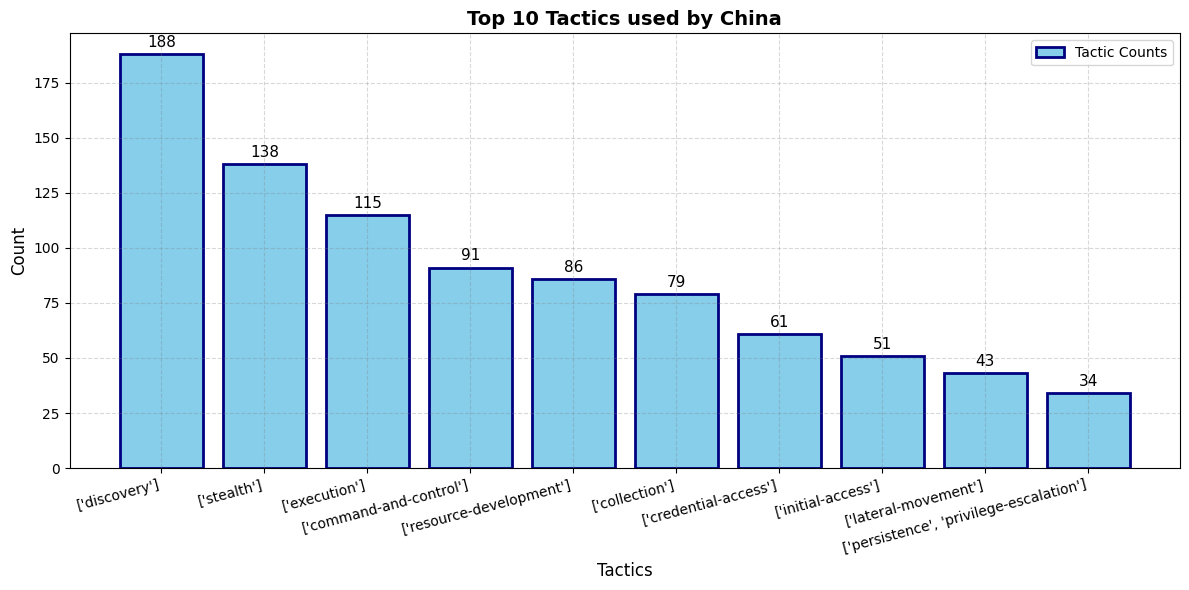

In [ ]:
china_df = main_df[main_df['Country'] == 'China']


tactic_counts = china_df['tactics'].value_counts()
tactics_top10 = tactic_counts.head(10).index.tolist()
counts_top10 = tactic_counts.head(10).values.tolist()

plt.figure(figsize=(12, 6)) # 텍스트가 겹치지 않도록 가로 길이를 조금 늘렸습니다.
plt.title('Top 10 Tactics used by China', fontsize=14, fontweight='bold')


# 바 그래프
x = np.arange(len(tactics_top10))
d_bar = plt.bar(x, counts_top10, align='center', edgecolor='navy',
                linewidth=2, tick_label=tactics_top10, color='skyblue', label='Tactic Counts')

# 바 라벨 표시
plt.bar_label(d_bar, padding=3, size=11)

# 조건부 색상 변경 (기존 sales > 200 조건 유지)
for i, bar in enumerate(d_bar):
    if counts_top10[i] > 200:
        bar.set_color('coral')
        bar.set_edgecolor('navy')
        bar.set_linewidth(2)    


# 그리드 및 레이블 설정
plt.grid(True, axis='both', color='gray', alpha=0.3, linestyle='--')
plt.xlabel('Tactics', fontsize=12)
plt.ylabel('Count', fontsize=12)

# X축 글자(Tactic 이름)가 길어서 겹치면 아래 주석(#)을 해제해서 비스듬히 돌려주세요.
plt.xticks(rotation=15, ha='right')

plt.legend()
plt.tight_layout() # 여백 자동 조절
plt.show()

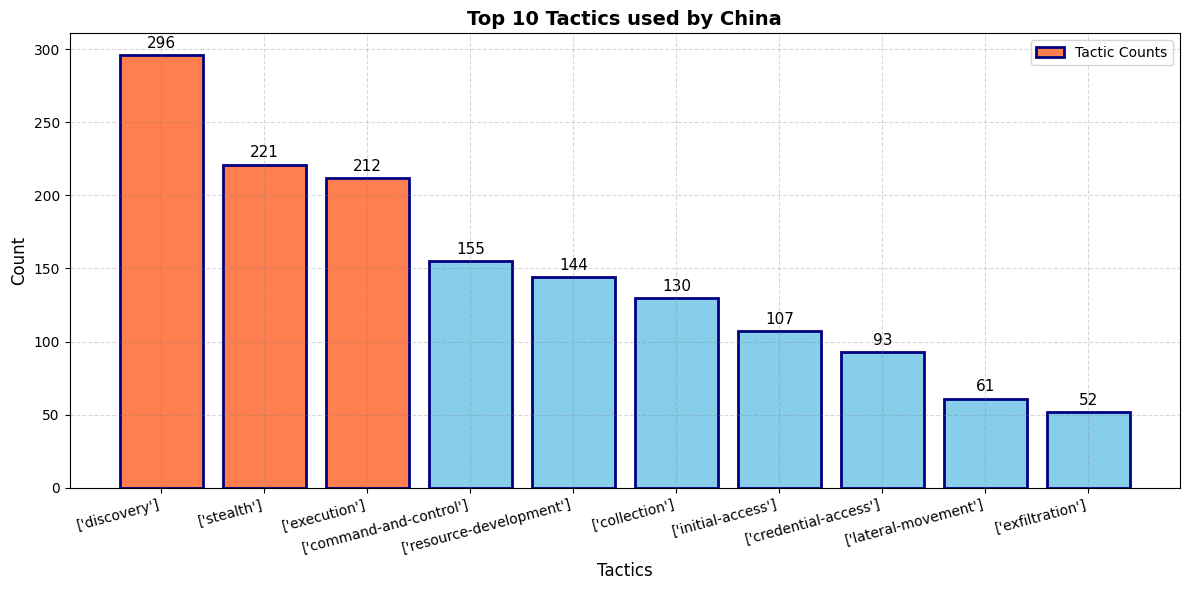

In [ ]:
#unknown인 나라들 예측값으로 채웠을때
china_e_df = main_df[main_df['Final_Country'] == 'China']


tactic_counts = china_e_df['tactics'].value_counts()
tactics_top10 = tactic_counts.head(10).index.tolist()
counts_top10 = tactic_counts.head(10).values.tolist()

plt.figure(figsize=(12, 6)) # 텍스트가 겹치지 않도록 가로 길이를 조금 늘렸습니다.
plt.title('Top 10 Tactics used by China', fontsize=14, fontweight='bold')


# 바 그래프
x = np.arange(len(tactics_top10))
d_bar = plt.bar(x, counts_top10, align='center', edgecolor='navy',
                linewidth=2, tick_label=tactics_top10, color='skyblue', label='Tactic Counts')

# 바 라벨 표시
plt.bar_label(d_bar, padding=3, size=11)

# 조건부 색상 변경 (기존 sales > 200 조건 유지)
for i, bar in enumerate(d_bar):
    if counts_top10[i] > 200:
        bar.set_color('coral')
        bar.set_edgecolor('navy')
        bar.set_linewidth(2)    


# 그리드 및 레이블 설정
plt.grid(True, axis='both', color='gray', alpha=0.3, linestyle='--')
plt.xlabel('Tactics', fontsize=12)
plt.ylabel('Count', fontsize=12)

# X축 글자(Tactic 이름)가 길어서 겹치면 아래 주석(#)을 해제해서 비스듬히 돌려주세요.
plt.xticks(rotation=15, ha='right')

plt.legend()
plt.tight_layout() # 여백 자동 조절
plt.show()

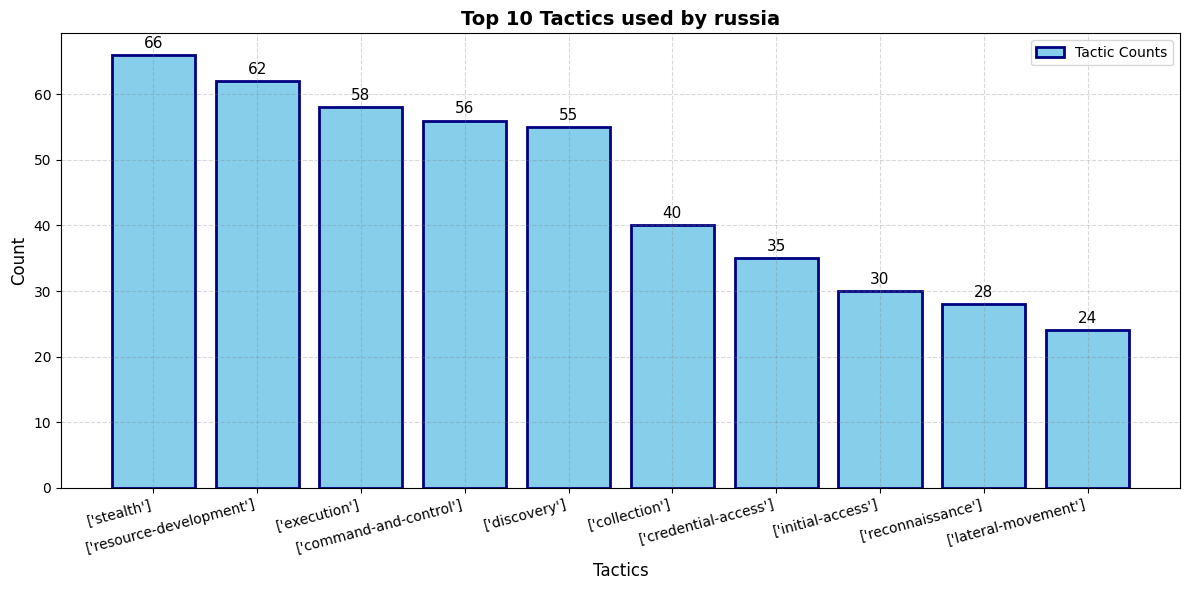

In [ ]:
russia_df = main_df[main_df['Country'] == 'Russia']


tactic_counts = russia_df['tactics'].value_counts()
tactics_top10 = tactic_counts.head(10).index.tolist()
counts_top10 = tactic_counts.head(10).values.tolist()

plt.figure(figsize=(12, 6)) # 텍스트가 겹치지 않도록 가로 길이를 조금 늘렸습니다.
plt.title('Top 10 Tactics used by russia', fontsize=14, fontweight='bold')


# 바 그래프
x = np.arange(len(tactics_top10))
d_bar = plt.bar(x, counts_top10, align='center', edgecolor='navy',
                linewidth=2, tick_label=tactics_top10, color='skyblue', label='Tactic Counts')

# 바 라벨 표시
plt.bar_label(d_bar, padding=3, size=11)

# 조건부 색상 변경 (기존 sales > 200 조건 유지)
for i, bar in enumerate(d_bar):
    if counts_top10[i] > 200:
        bar.set_color('coral')
        bar.set_edgecolor('navy')
        bar.set_linewidth(2)    


# 그리드 및 레이블 설정
plt.grid(True, axis='both', color='gray', alpha=0.3, linestyle='--')
plt.xlabel('Tactics', fontsize=12)
plt.ylabel('Count', fontsize=12)

# X축 글자(Tactic 이름)가 길어서 겹치면 아래 주석(#)을 해제해서 비스듬히 돌려주세요.
plt.xticks(rotation=15, ha='right')

plt.legend()
plt.tight_layout() # 여백 자동 조절
plt.show()

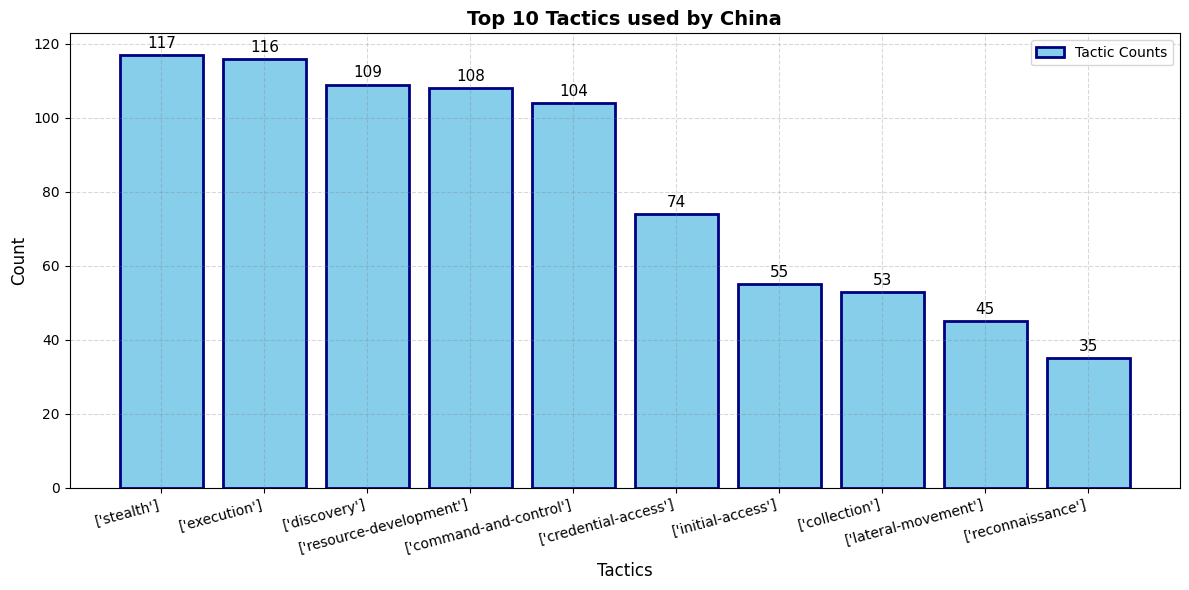

In [ ]:
#unknown인 나라들 예측값으로 채웠을때
Russia_e_df = main_df[main_df['Final_Country'] == 'Russia']


tactic_counts = Russia_e_df['tactics'].value_counts()
tactics_top10 = tactic_counts.head(10).index.tolist()
counts_top10 = tactic_counts.head(10).values.tolist()

plt.figure(figsize=(12, 6)) # 텍스트가 겹치지 않도록 가로 길이를 조금 늘렸습니다.
plt.title('Top 10 Tactics used by China', fontsize=14, fontweight='bold')


# 바 그래프
x = np.arange(len(tactics_top10))
d_bar = plt.bar(x, counts_top10, align='center', edgecolor='navy',
                linewidth=2, tick_label=tactics_top10, color='skyblue', label='Tactic Counts')

# 바 라벨 표시
plt.bar_label(d_bar, padding=3, size=11)

# 조건부 색상 변경 (기존 sales > 200 조건 유지)
for i, bar in enumerate(d_bar):
    if counts_top10[i] > 200:
        bar.set_color('coral')
        bar.set_edgecolor('navy')
        bar.set_linewidth(2)    


# 그리드 및 레이블 설정
plt.grid(True, axis='both', color='gray', alpha=0.3, linestyle='--')
plt.xlabel('Tactics', fontsize=12)
plt.ylabel('Count', fontsize=12)

# X축 글자(Tactic 이름)가 길어서 겹치면 아래 주석(#)을 해제해서 비스듬히 돌려주세요.
plt.xticks(rotation=15, ha='right')

plt.legend()
plt.tight_layout() # 여백 자동 조절
plt.show()

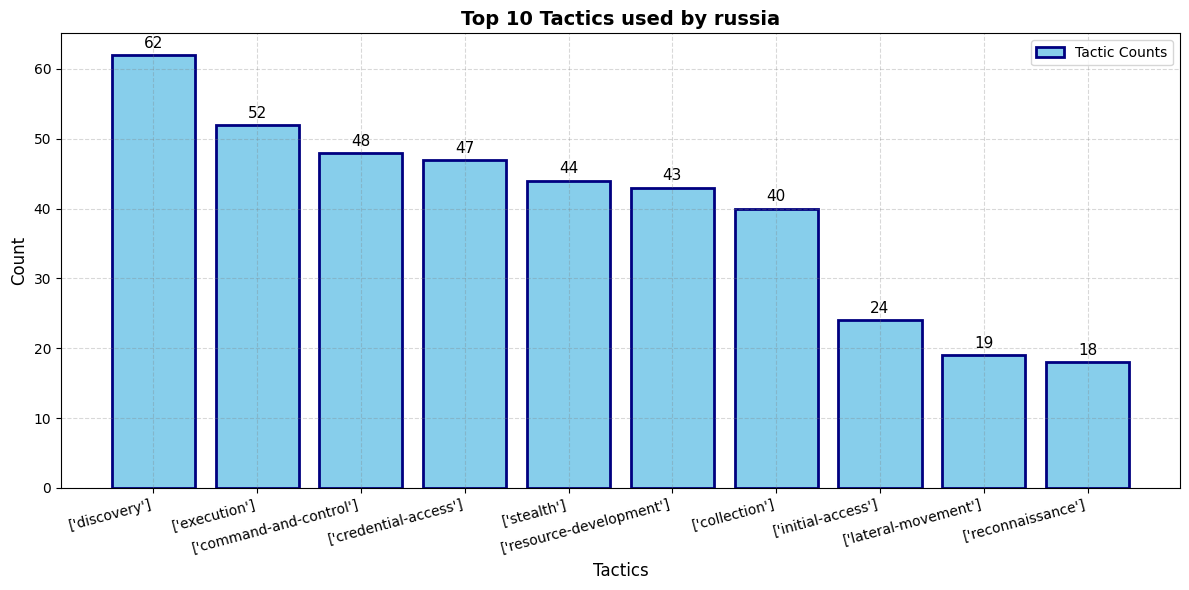

In [ ]:
iran_df = main_df[main_df['Country'] == 'Iran']


tactic_counts = iran_df['tactics'].value_counts()
tactics_top10 = tactic_counts.head(10).index.tolist()
counts_top10 = tactic_counts.head(10).values.tolist()

plt.figure(figsize=(12, 6)) # 텍스트가 겹치지 않도록 가로 길이를 조금 늘렸습니다.
plt.title('Top 10 Tactics used by russia', fontsize=14, fontweight='bold')


# 바 그래프
x = np.arange(len(tactics_top10))
d_bar = plt.bar(x, counts_top10, align='center', edgecolor='navy',
                linewidth=2, tick_label=tactics_top10, color='skyblue', label='Tactic Counts')

# 바 라벨 표시
plt.bar_label(d_bar, padding=3, size=11)

# 조건부 색상 변경 (기존 sales > 200 조건 유지)
for i, bar in enumerate(d_bar):
    if counts_top10[i] > 200:
        bar.set_color('coral')
        bar.set_edgecolor('navy')
        bar.set_linewidth(2)    


# 그리드 및 레이블 설정
plt.grid(True, axis='both', color='gray', alpha=0.3, linestyle='--')
plt.xlabel('Tactics', fontsize=12)
plt.ylabel('Count', fontsize=12)

# X축 글자(Tactic 이름)가 길어서 겹치면 아래 주석(#)을 해제해서 비스듬히 돌려주세요.
plt.xticks(rotation=15, ha='right')

plt.legend()
plt.tight_layout() # 여백 자동 조절
plt.show()

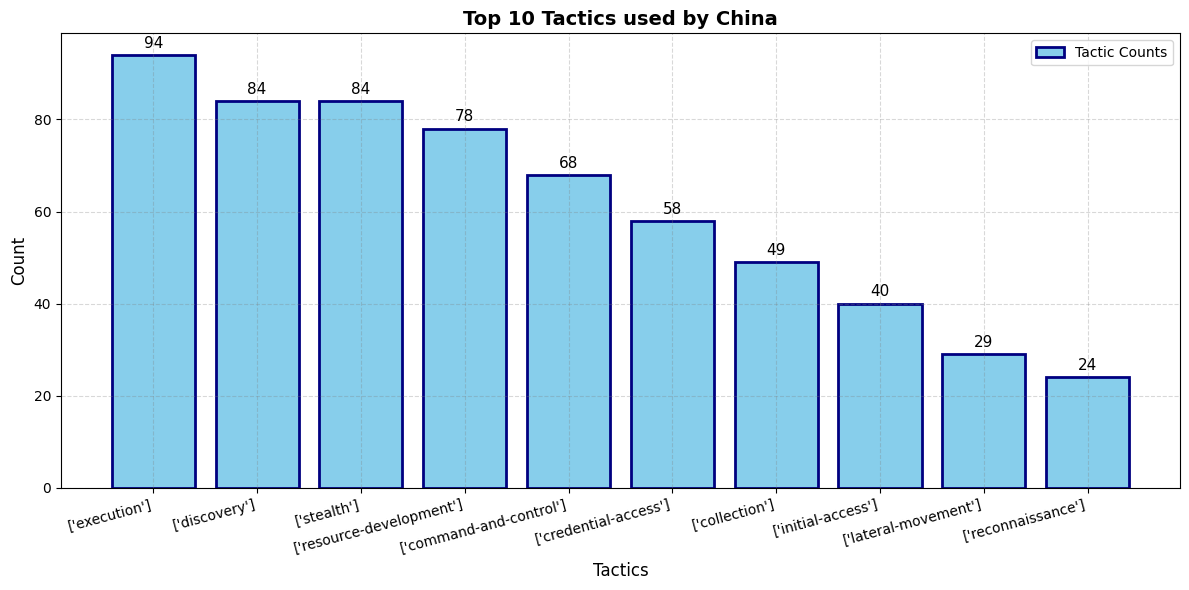

In [ ]:
#unknown인 나라들 예측값으로 채웠을때
iran_e_df = main_df[main_df['Final_Country'] == 'Iran']

tactic_counts = iran_e_df['tactics'].value_counts()
tactics_top10 = tactic_counts.head(10).index.tolist()
counts_top10 = tactic_counts.head(10).values.tolist()

plt.figure(figsize=(12, 6)) # 텍스트가 겹치지 않도록 가로 길이를 조금 늘렸습니다.
plt.title('Top 10 Tactics used by China', fontsize=14, fontweight='bold')


# 바 그래프
x = np.arange(len(tactics_top10))
d_bar = plt.bar(x, counts_top10, align='center', edgecolor='navy',
                linewidth=2, tick_label=tactics_top10, color='skyblue', label='Tactic Counts')

# 바 라벨 표시
plt.bar_label(d_bar, padding=3, size=11)

# 조건부 색상 변경 (기존 sales > 200 조건 유지)
for i, bar in enumerate(d_bar):
    if counts_top10[i] > 200:
        bar.set_color('coral')
        bar.set_edgecolor('navy')
        bar.set_linewidth(2)    


# 그리드 및 레이블 설정
plt.grid(True, axis='both', color='gray', alpha=0.3, linestyle='--')
plt.xlabel('Tactics', fontsize=12)
plt.ylabel('Count', fontsize=12)

# X축 글자(Tactic 이름)가 길어서 겹치면 아래 주석(#)을 해제해서 비스듬히 돌려주세요.
plt.xticks(rotation=15, ha='right')

plt.legend()
plt.tight_layout() # 여백 자동 조절
plt.show()

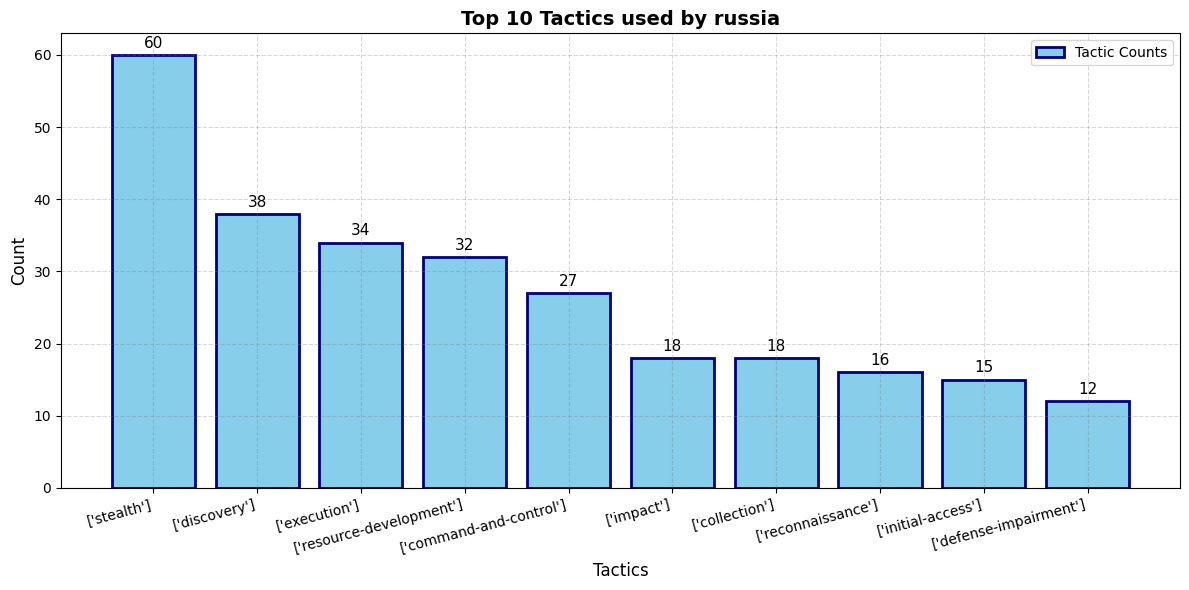

In [ ]:
north_df = main_df[main_df['Country'] == 'North Korea']


tactic_counts = north_df['tactics'].value_counts()
tactics_top10 = tactic_counts.head(10).index.tolist()
counts_top10 = tactic_counts.head(10).values.tolist()

plt.figure(figsize=(12, 6)) # 텍스트가 겹치지 않도록 가로 길이를 조금 늘렸습니다.
plt.title('Top 10 Tactics used by russia', fontsize=14, fontweight='bold')


# 바 그래프
x = np.arange(len(tactics_top10))
d_bar = plt.bar(x, counts_top10, align='center', edgecolor='navy',
                linewidth=2, tick_label=tactics_top10, color='skyblue', label='Tactic Counts')

# 바 라벨 표시
plt.bar_label(d_bar, padding=3, size=11)

# 조건부 색상 변경 (기존 sales > 200 조건 유지)
for i, bar in enumerate(d_bar):
    if counts_top10[i] > 200:
        bar.set_color('coral')
        bar.set_edgecolor('navy')
        bar.set_linewidth(2)    


# 그리드 및 레이블 설정
plt.grid(True, axis='both', color='gray', alpha=0.3, linestyle='--')
plt.xlabel('Tactics', fontsize=12)
plt.ylabel('Count', fontsize=12)

# X축 글자(Tactic 이름)가 길어서 겹치면 아래 주석(#)을 해제해서 비스듬히 돌려주세요.
plt.xticks(rotation=15, ha='right')

plt.legend()
plt.tight_layout() # 여백 자동 조절
plt.show()

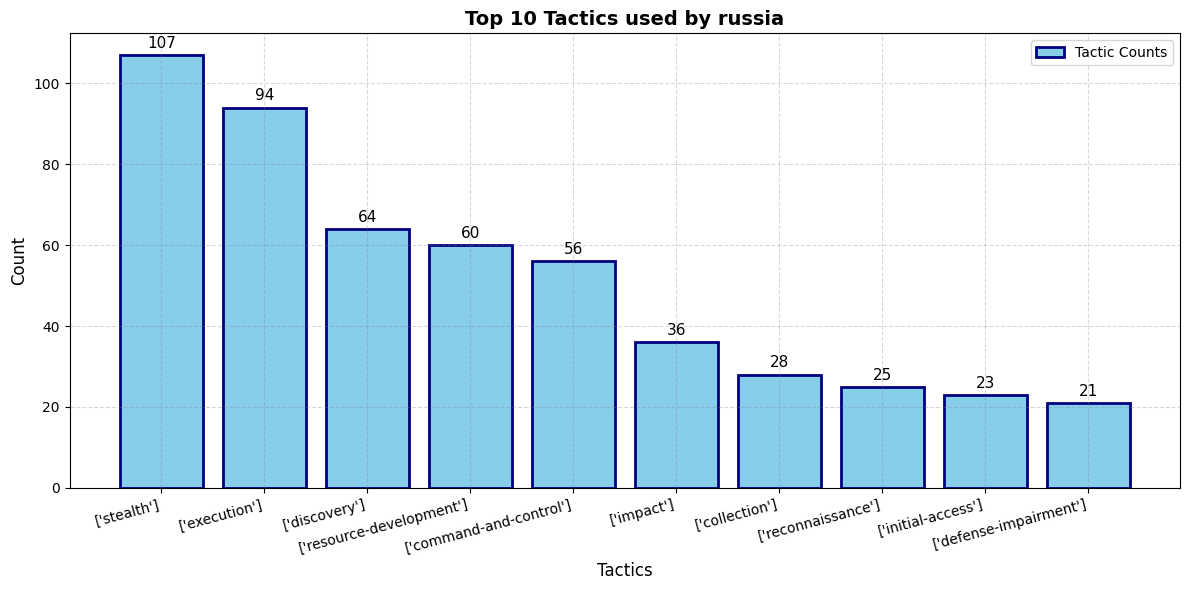

In [ ]:
#unknown인 나라들 예측값으로 채웠을때
north_e_df = main_df[main_df['Final_Country'] == 'North Korea']

tactic_counts = north_e_df['tactics'].value_counts()
tactics_top10 = tactic_counts.head(10).index.tolist()
counts_top10 = tactic_counts.head(10).values.tolist()

plt.figure(figsize=(12, 6)) # 텍스트가 겹치지 않도록 가로 길이를 조금 늘렸습니다.
plt.title('Top 10 Tactics used by russia', fontsize=14, fontweight='bold')


# 바 그래프
x = np.arange(len(tactics_top10))
d_bar = plt.bar(x, counts_top10, align='center', edgecolor='navy',
                linewidth=2, tick_label=tactics_top10, color='skyblue', label='Tactic Counts')

# 바 라벨 표시
plt.bar_label(d_bar, padding=3, size=11)

# 조건부 색상 변경 (기존 sales > 200 조건 유지)
for i, bar in enumerate(d_bar):
    if counts_top10[i] > 200:
        bar.set_color('coral')
        bar.set_edgecolor('navy')
        bar.set_linewidth(2)    


# 그리드 및 레이블 설정
plt.grid(True, axis='both', color='gray', alpha=0.3, linestyle='--')
plt.xlabel('Tactics', fontsize=12)
plt.ylabel('Count', fontsize=12)

# X축 글자(Tactic 이름)가 길어서 겹치면 아래 주석(#)을 해제해서 비스듬히 돌려주세요.
plt.xticks(rotation=15, ha='right')

plt.legend()
plt.tight_layout() # 여백 자동 조절
plt.show()

In [ ]:
main_df['Country'].value_counts()

Country
China          1111
Russia          566
Iran            487
North Korea     338
India           133
Vietnam          78
Pakistan         46
Turkey           11
Name: count, dtype: int64

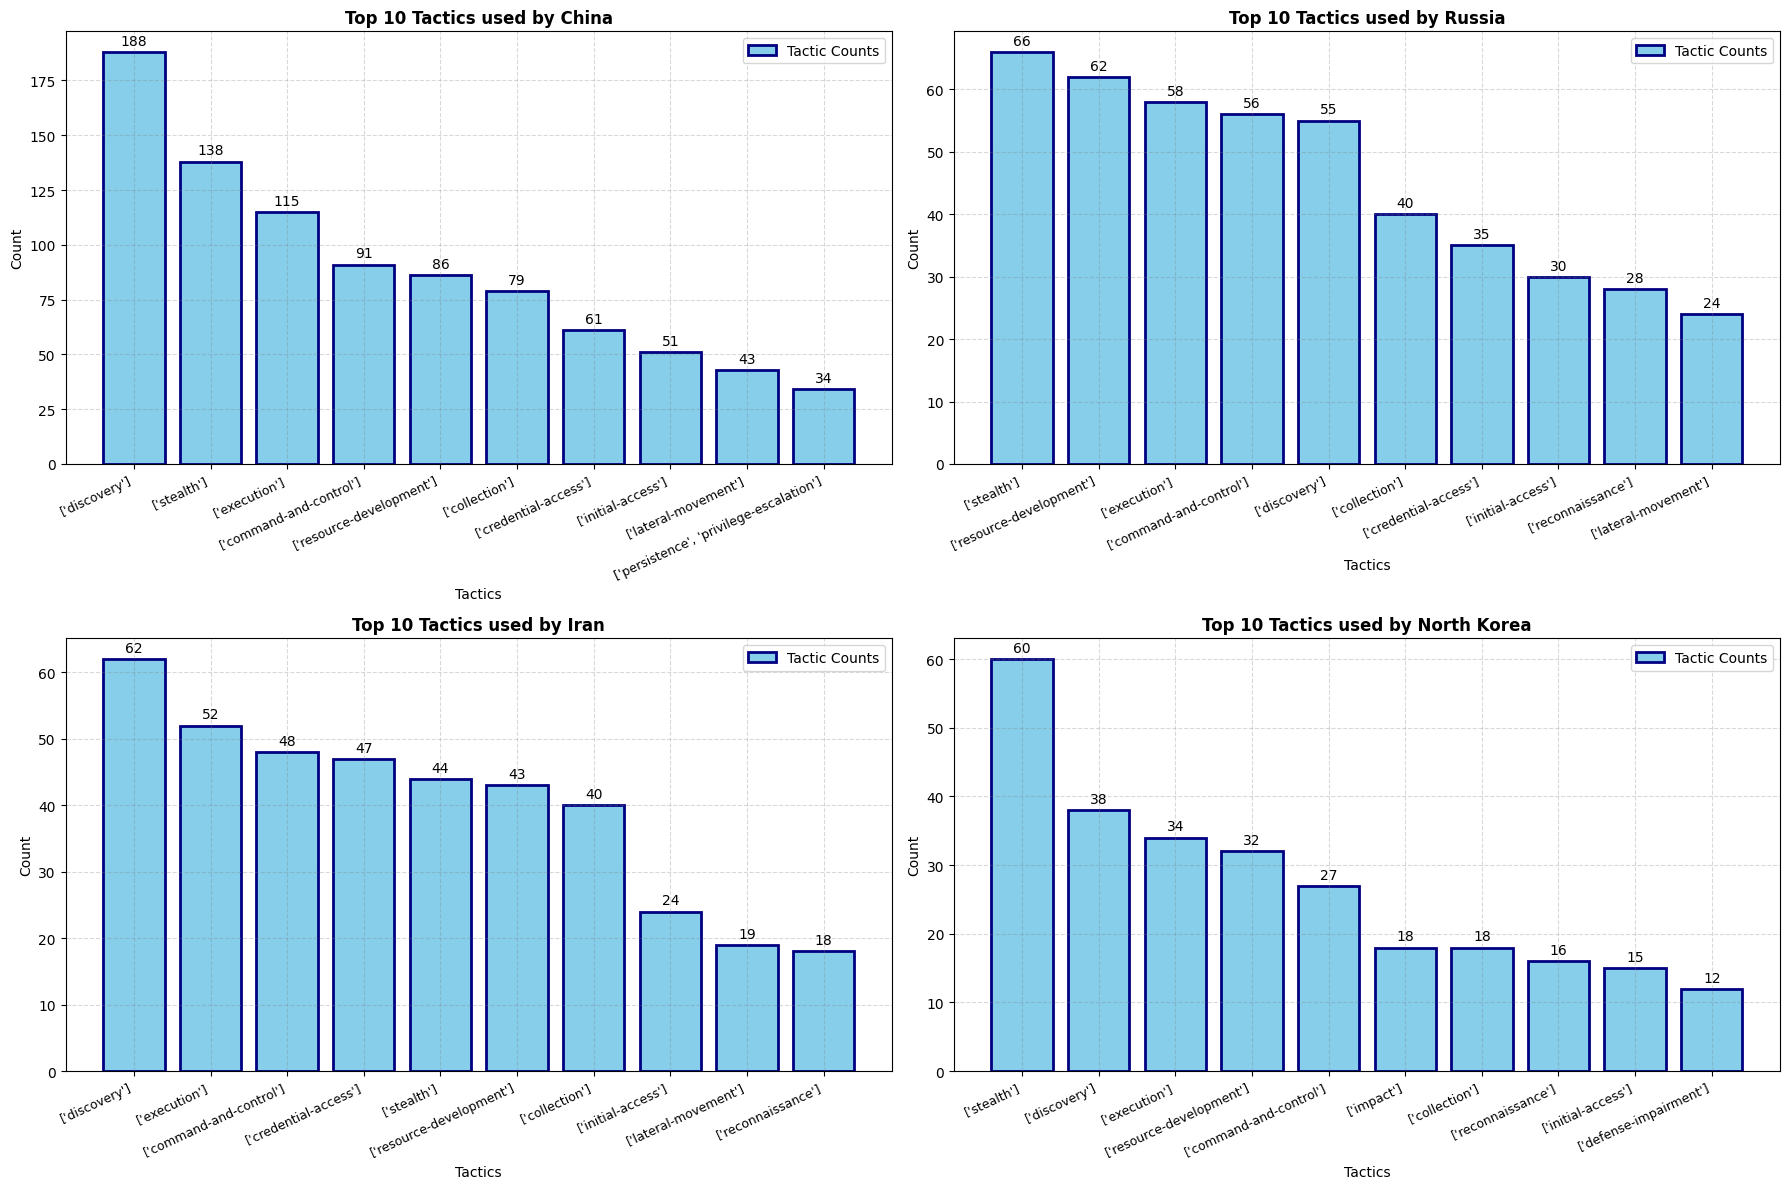

In [ ]:
countries = ['China', 'Russia', 'Iran', 'North Korea']

# 3. 🎨 2x2 서브플롯 틀 만들기 (전체 화면 크기를 키워야 안 겹칩니다)
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
# 2차원 배열인 axes를 1차원(4개짜리)으로 펴서 반복문 돌리기 편하게 만듭니다.
axes_flat = axes.flatten() 

# 4. 반복문을 돌며 국가별로 그래프 그리기
for idx, country in enumerate(countries):
    ax = axes_flat[idx] # 현재 그릴 서브플롯 축(axis) 선택
    
    # 4-1. 해당 국가 데이터 필터링 및 상위 10개 솎아내기
    country_df = main_df[main_df['Country'] == country]
    tactic_counts = country_df['tactics'].value_counts()
    tactics_top10 = tactic_counts.head(10).index.tolist()
    counts_top10 = tactic_counts.head(10).values.tolist()
    
    # 데이터가 부족할 경우를 대비한 안전장치
    if not counts_top10:
        ax.set_title(f'No Data for {country}')
        continue
        
    # 4-2. 바 그래프 그리기 (plt.bar 대신 ax.bar 사용)
    x = np.arange(len(tactics_top10))
    d_bar = ax.bar(x, counts_top10, align='center', edgecolor='navy',
                   linewidth=2, tick_label=tactics_top10, color='skyblue', label='Tactic Counts')
    
    # 바 라벨 표시 (plt.bar_label 대신 ax.bar_label 사용)
    ax.bar_label(d_bar, padding=3, size=10)
    
    # 4-3. 조건부 색상 변경 (기존 200 기준 유지)
    for i, bar in enumerate(d_bar):
        if counts_top10[i] > 200:
            bar.set_color('coral')
            bar.set_edgecolor('navy')
            bar.set_linewidth(2)    
    
    # 4-4. 개별 차트 스타일링 (plt 대신 ax 명령어로 변경)
    ax.set_title(f'Top 10 Tactics used by {country}', fontsize=12, fontweight='bold')
    ax.grid(True, axis='both', color='gray', alpha=0.3, linestyle='--')
    ax.set_xlabel('Tactics', fontsize=10)
    ax.set_ylabel('Count', fontsize=10)
    
    # X축 글자 돌리기 및 오른쪽 정렬 (텍틱 이름 겹침 방지)
    ax.set_xticklabels(tactics_top10, rotation=25, ha='right', fontsize=9)
    ax.legend(loc='upper right')

# 5. 전체 레이아웃 다듬고 출력
plt.tight_layout() # 서브플롯 간의 간격을 자동으로 조절해 겹치지 않게 해줍니다.
plt.show()

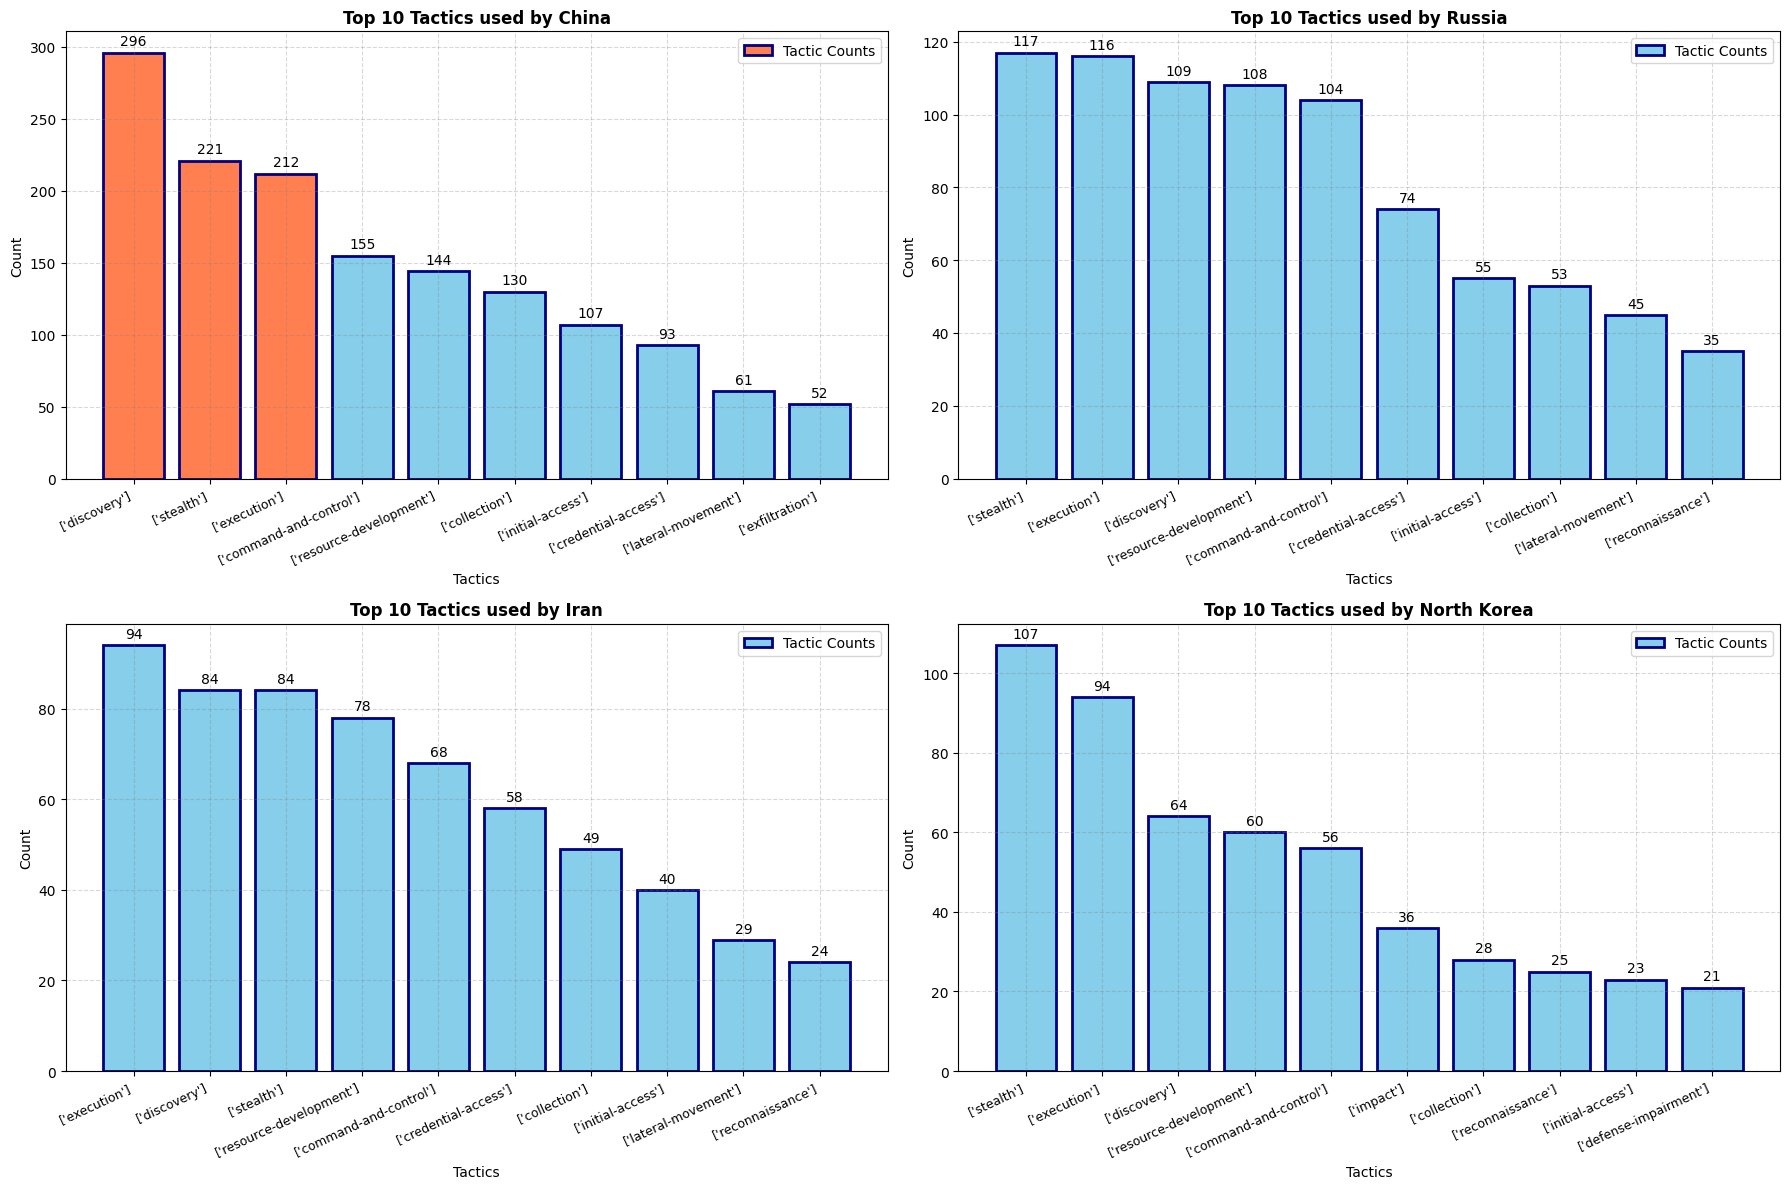

In [ ]:
countries = ['China', 'Russia', 'Iran', 'North Korea']

# 3. 🎨 2x2 서브플롯 틀 만들기 (전체 화면 크기를 키워야 안 겹칩니다)
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
# 2차원 배열인 axes를 1차원(4개짜리)으로 펴서 반복문 돌리기 편하게 만듭니다.
axes_flat = axes.flatten() 

# 4. 반복문을 돌며 국가별로 그래프 그리기
for idx, country in enumerate(countries):
    ax = axes_flat[idx] # 현재 그릴 서브플롯 축(axis) 선택
    
    # 4-1. 해당 국가 데이터 필터링 및 상위 10개 솎아내기
    country_df = main_df[main_df['Final_Country'] == country]
    tactic_counts = country_df['tactics'].value_counts()
    tactics_top10 = tactic_counts.head(10).index.tolist()
    counts_top10 = tactic_counts.head(10).values.tolist()
    
    # 데이터가 부족할 경우를 대비한 안전장치
    if not counts_top10:
        ax.set_title(f'No Data for {country}')
        continue
        
    # 4-2. 바 그래프 그리기 (plt.bar 대신 ax.bar 사용)
    x = np.arange(len(tactics_top10))
    d_bar = ax.bar(x, counts_top10, align='center', edgecolor='navy',
                   linewidth=2, tick_label=tactics_top10, color='skyblue', label='Tactic Counts')
    
    # 바 라벨 표시 (plt.bar_label 대신 ax.bar_label 사용)
    ax.bar_label(d_bar, padding=3, size=10)
    
    # 4-3. 조건부 색상 변경 (기존 200 기준 유지)
    for i, bar in enumerate(d_bar):
        if counts_top10[i] > 200:
            bar.set_color('coral')
            bar.set_edgecolor('navy')
            bar.set_linewidth(2)    
    
    # 4-4. 개별 차트 스타일링 (plt 대신 ax 명령어로 변경)
    ax.set_title(f'Top 10 Tactics used by {country}', fontsize=12, fontweight='bold')
    ax.grid(True, axis='both', color='gray', alpha=0.3, linestyle='--')
    ax.set_xlabel('Tactics', fontsize=10)
    ax.set_ylabel('Count', fontsize=10)
    
    # X축 글자 돌리기 및 오른쪽 정렬 (텍틱 이름 겹침 방지)
    ax.set_xticklabels(tactics_top10, rotation=25, ha='right', fontsize=9)
    ax.legend(loc='upper right')

# 5. 전체 레이아웃 다듬고 출력
plt.tight_layout() # 서브플롯 간의 간격을 자동으로 조절해 겹치지 않게 해줍니다.
plt.show()

In [ ]:
china_df = main_df[main_df['Country'] == 'China']
china_e_df = main_df[main_df['Final_Country'] == 'China']
tactic_counts = china_df['tactics'].value_counts()
tactic_e_counts = china_e_df['tactics'].value_counts()
china_10 = tactic_counts.head(10)
china_e_10 = tactic_e_counts.head(10)

In [ ]:
df1 = china_10.reset_index()
df1.columns = ['Tactics', 'Counts_Country']
df1['Rank_Country'] = range(1, len(df1) + 1) # 1~10등 부여

df2 = china_e_10.reset_index()
df2.columns = ['Tactics', 'Counts_FinalCountry']
df2['Rank_FinalCountry'] = range(1, len(df2) + 1) # 1~10등 부여

In [ ]:
merge_df = pd.merge(df1, df2, on='Tactics', how='outer')
merge_df['Rank_Difference'] = (merge_df['Rank_Country'] - merge_df['Rank_FinalCountry']).abs()

In [ ]:
merge_df['Rank_Difference']

0     0.0
1     0.0
2     1.0
3     0.0
4     0.0
5     NaN
6     1.0
7     0.0
8     NaN
9     0.0
10    0.0
Name: Rank_Difference, dtype: float64

In [ ]:
#
# 1. 대상 국가 리스트 정의
target_countries = ['China','Russia', 'Iran', 'North Korea']

# 2. 국가별 결과를 저장할 딕셔너리 생성
country_rank_diffs = {}

# 3. 반복문을 돌며 국가별 순위 차이 계산
for country in target_countries:
    # 각 기준 컬럼에서 해당 국가 필터링
    df_country = main_df[main_df['Country'] == country]
    df_final_country = main_df[main_df['Final_Country'] == country]
    
    # tactics 빈도수 계산 후 상위 10개 추출
    counts_c = df_country['tactics'].value_counts().head(10)
    counts_fc = df_final_country['tactics'].value_counts().head(10)
    
    # df1 (Country 기준 표 만들기)
    df1 = counts_c.reset_index()
    df1.columns = ['Tactics', 'Counts_Country']
    df1['Rank_Country'] = range(1, len(df1) + 1)
    
    # df2 (Final_Country 기준 표 만들기)
    df2 = counts_fc.reset_index()
    df2.columns = ['Tactics', 'Counts_FinalCountry']
    df2['Rank_FinalCountry'] = range(1, len(df2) + 1)
    
    # 두 기준 병합 (둘 중 한 곳에만 있는 Tactic도 누락되지 않도록 outer join)
    merge_df = pd.merge(df1, df2, on='Tactics', how='outer')
    
    merge_df['Rank_Difference'] = (merge_df['Rank_Country'] - merge_df['Rank_FinalCountry']).abs()
    
    # 결과를 딕셔너리에 저장 (국가 이름을 Key로 사용)
    country_rank_diffs[country] = merge_df

print("==========================================================")
print(" 중국순위 비교 및 차이")
print("==========================================================")
print(country_rank_diffs['China'][['Tactics', 'Rank_Country', 'Rank_FinalCountry', 'Rank_Difference']])

print("==========================================================")
print("🇷🇺 러시아 (Russia) 순위 비교 및 차이")
print("==========================================================")
print(country_rank_diffs['Russia'][['Tactics', 'Rank_Country', 'Rank_FinalCountry', 'Rank_Difference']])


 중국순위 비교 및 차이
                                    Tactics  Rank_Country  Rank_FinalCountry  \
0                            ['collection']           6.0                6.0   
1                   ['command-and-control']           4.0                4.0   
2                     ['credential-access']           7.0                8.0   
3                             ['discovery']           1.0                1.0   
4                             ['execution']           3.0                3.0   
5                          ['exfiltration']           NaN               10.0   
6                        ['initial-access']           8.0                7.0   
7                      ['lateral-movement']           9.0                9.0   
8   ['persistence', 'privilege-escalation']          10.0                NaN   
9                  ['resource-development']           5.0                5.0   
10                              ['stealth']           2.0                2.0   

    Rank_Difference  
0  

In [ ]:
print("\n==========================================================")
print("🇮🇷 이란 (Iran) 순위 비교 및 차이")
print("==========================================================")
print(country_rank_diffs['Iran'][['Tactics', 'Rank_Country', 'Rank_FinalCountry', 'Rank_Difference']])

print("\n==========================================================")
print("🇰🇷 북한 (North Korea) 순위 비교 및 차이")
print("==========================================================")
print(country_rank_diffs['North Korea'][['Tactics', 'Rank_Country', 'Rank_FinalCountry', 'Rank_Difference']])


🇮🇷 이란 (Iran) 순위 비교 및 차이
                    Tactics  Rank_Country  Rank_FinalCountry  Rank_Difference
0            ['collection']             7                  7                0
1   ['command-and-control']             3                  5                2
2     ['credential-access']             4                  6                2
3             ['discovery']             1                  2                1
4             ['execution']             2                  1                1
5        ['initial-access']             8                  8                0
6      ['lateral-movement']             9                  9                0
7        ['reconnaissance']            10                 10                0
8  ['resource-development']             6                  4                2
9               ['stealth']             5                  3                2

🇰🇷 북한 (North Korea) 순위 비교 및 차이
                    Tactics  Rank_Country  Rank_FinalCountry  Rank_Difference
0      

### 이거 cot 전체 description이랑 mitre 전체 description sklearn 사용해서 텍스트 벡터화 해서 숫자별로 바꾸고 코사인 유사도 연산해서 행렬로 곱해서 유사도 도출해서 결측치만 채웠습니다.
### 나라, TACTICS로 묶어서 그룹화 해서 비교해봤을때 결과 거의 비슷한거 보니 군집화 할때 사용해도 될듯


In [ ]:
china_df = main_df[main_df['Country'] == 'China']
china_e_df = main_df[main_df['Final_Country'] == 'China']
tactic_counts = china_df['tactics'].value_counts()
tactic_e_counts = china_e_df['tactics'].value_counts()
china_10 = tactic_counts.head(10)
china_e_10 = tactic_e_counts.head(10)

In [ ]:
target_countries = ['China', 'Russia', 'Iran', 'North Korea']

country_10_res = {}
country_e_10_res = {}

for country in target_countries:
    # c_df = main_df[main_df['Country'] == country]
    # country_10_res[country] = c_df['tactics'].value_counts().head(10)
    
    fe_df = main_df[main_df['Final_Country'] == country]
    country_e_10_res[country] = fe_df['tactics'].value_counts().head(10)

In [ ]:
country_10_res['China']
#중국의 경우
# discovery 정찰 탐색
# stealth
# execution
# command-and-control
# resource-development

tactics
['discovery']                              188
['stealth']                                138
['execution']                              115
['command-and-control']                     91
['resource-development']                    86
['collection']                              79
['credential-access']                       61
['initial-access']                          51
['lateral-movement']                        43
['persistence', 'privilege-escalation']     34
Name: count, dtype: int64

In [ ]:
country_10_res['Russia']

tactics
['stealth']                 66
['resource-development']    62
['execution']               58
['command-and-control']     56
['discovery']               55
['collection']              40
['credential-access']       35
['initial-access']          30
['reconnaissance']          28
['lateral-movement']        24
Name: count, dtype: int64

In [ ]:
country_10_res['Iran']

tactics
['discovery']               62
['execution']               52
['command-and-control']     48
['credential-access']       47
['stealth']                 44
['resource-development']    43
['collection']              40
['initial-access']          24
['lateral-movement']        19
['reconnaissance']          18
Name: count, dtype: int64

In [ ]:
country_10_res['North Korea']
# stealth 보통 비트코인이나 금융관련 고도화된 보안이 있는곳을 해킹하는 경우 걸리면 안됨 (횟수가 많은건 실패해도 여러번 시도했다는뜻)
# discovery 침투에 성공해서 내부를 탐색하는 단계
# execution 다른 전술들을 시작하기 전에 필요한 단계 (다른 단계들과 + 해서 생각해볼수 있음)
# resource 공격에 필요한 준비 (다크웹 해킹 툴이나 타깃 회사 계정 등)
# command
#
#
#
#initial 
#defense 방어무력화

tactics
['stealth']                 60
['discovery']               38
['execution']               34
['resource-development']    32
['command-and-control']     27
['impact']                  18
['collection']              18
['reconnaissance']          16
['initial-access']          15
['defense-impairment']      12
Name: count, dtype: int64

In [ ]:
tactic_order = {
    'reconnaissance': 1,            # 사전 정찰
    'resource-development': 2,      # 자원 개발 (인프라 구축)
    'initial-access': 3,            # 최초 침투
    'execution': 4,                 # 명령 실행
    'persistence': 5,               # 지속성 확보 (백도어 등)
    'privilege-escalation': 6,      # 권한 상승
    'stealth': 7,                   # 은닉 행위 (방어 우회 계열)
    'defense-impairment': 8,        # 방어 무력화 (방어 우회 계열)
    'credential-access': 9,         # 계정 탈취
    'discovery': 10,                # 내부 정찰 (시스템 탐색)
    'lateral-movement': 11,         # 내부 이동 (망 내 확산)
    'collection': 12,               # 데이터 수집
    'command-and-control': 13,      # 명령 및 제어 (C2)
    'exfiltration': 14,             # 데이터 유출
    'impact': 15                    # 시스템 파괴 및 영향
}

In [ ]:
target_countries = ['China', 'Russia', 'Iran', 'North Korea']

country_10_res = {}
country_e_10_res = {}

for country in target_countries:
    # c_df = main_df[main_df['Country'] == country]
    # country_10_res[country] = c_df['tactics'].value_counts().head(10)
    
    fe_df = main_df[main_df['Final_Country'] == country]
    country_e_10_res[country] = fe_df['tactics'].value_counts().head(10).to_dict()

In [ ]:
# 국가별 상위 10개 Tactic의 총합을 저장할 딕셔너리
country_top10_totals = {}
suc = {}

# 1. 딕셔너리의 key(국가명)와 value(상위 10개 데이터)를 꺼냅니다.
for country, tactics_data in country_e_10_res.items():
    total_sum = 0
    success = 0
    
    # 2. enumerate를 사용해 각 Tactic의 순위(idx), 이름(tactic), 빈도수(count)를 순회합니다.
    # tactics_data.items()를 하면 (Tactic이름, 빈도수)가 나옵니다.
    for idx, (tactic, count) in enumerate(tactics_data.items()):
        total_sum += count
        tactic_lower = str(tactic).lower()
        if 'collection' in tactic_lower or 'exfiltration' in tactic_lower or 'impact' in tactic_lower:
            success += count
        
    # 국가별 총합 저장
    country_top10_totals[country] = total_sum
    suc[country] = success


print(country_top10_totals)
print(suc)
print(f"중국:{round(suc['China'] / country_top10_totals['China']*100)}%")
print(f"북한:{round(suc['North Korea'] / country_top10_totals['North Korea']*100)}%")
print(f"러시아:{round(suc['Russia'] / country_top10_totals['Russia']*100)}%")
print(f"이란:{round(suc['Iran'] / country_top10_totals['Iran']*100)}%")

{'China': 1339, 'Russia': 919, 'Iran': 608, 'North Korea': 549}
{'China': 110, 'Russia': 69, 'Iran': 53, 'North Korea': 58}
중국:8%
북한:11%
러시아:8%
이란:9%


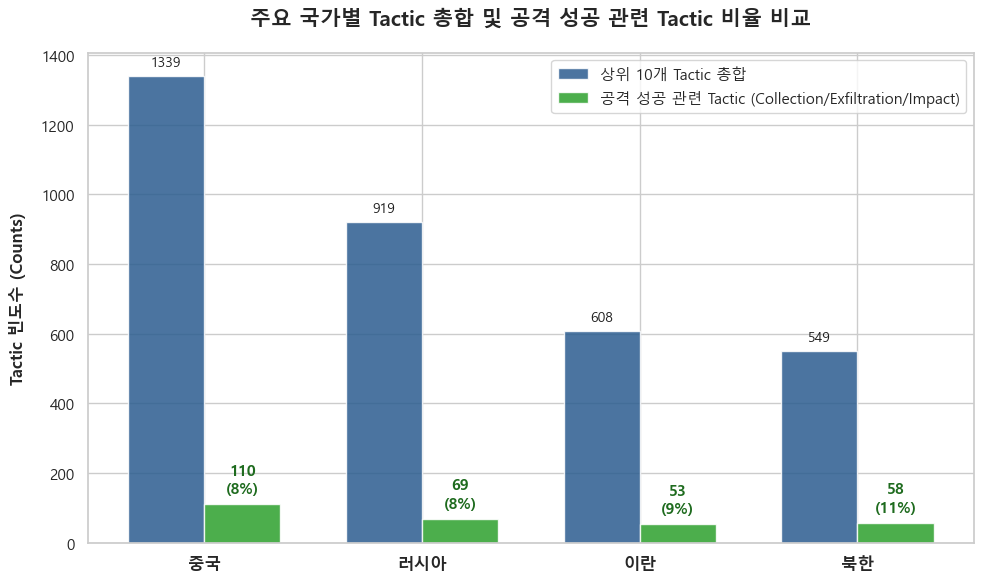

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# =========================================================================
# 1. [이전 단계 코드] 변수 확인 (실제 데이터와 연동)
# =========================================================================
# 이미 위에서 country_top10_totals와 suc 딕셔너리가 생성되어 있으므로 
# 아래 리스트와 매핑용 딕셔너리만 추가로 정의해 줍니다.
countries = ["China", "Russia", "Iran", "North Korea"]
korean_names = {
    "China": "중국",
    "Russia": "러시아",
    "Iran": "이란",
    "North Korea": "북한",
}

totals_val = [country_top10_totals[c] for c in countries]
suc_val = [suc[c] for c in countries]
percentages = [round(suc[c] / country_top10_totals[c] * 100) for c in countries]

# =========================================================================
# 2. 🎨 그래프 스타일 및 한글 폰트 설정
# =========================================================================
sns.set_theme(style="whitegrid")

# 시스템 환경에 맞는 폰트 설정 (윈도우: Malgun Gothic / 맥 OS: AppleGothic)
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# =========================================================================
# 3. 📊 그룹 바 차트(Grouped Bar Chart) 그리기
# =========================================================================
x = np.arange(len(countries))
width = 0.35  # 바 너비

fig, ax1 = plt.subplots(figsize=(10, 6))

# PPT 발표용 톤앤매너 테마 (차분한 네이비 & 직관적인 그린)
bar1 = ax1.bar(
    x - width / 2,
    totals_val,
    width,
    label="상위 10개 Tactic 총합",
    color="#2b5c8f",
    alpha=0.85,
)
bar2 = ax1.bar(
    x + width / 2,
    suc_val,
    width,
    label="공격 성공 관련 Tactic (Collection/Exfiltration/Impact)",
    color="#2ca02c",
    alpha=0.85,
)

# 축 라벨 및 타이틀 세팅
ax1.set_ylabel(
    "Tactic 빈도수 (Counts)", fontsize=12, fontweight="bold", labelpad=10
)
ax1.set_title(
    "주요 국가별 Tactic 총합 및 공격 성공 관련 Tactic 비율 비교",
    fontsize=15,
    fontweight="bold",
    pad=20,
)
ax1.set_xticks(x)
ax1.set_xticklabels(
    [korean_names[c] for c in countries], fontsize=12, fontweight="bold"
)
ax1.legend(loc="upper right", frameon=True)

# =========================================================================
# 4. 🏷️ 바 상단에 데이터 수치 및 비율(%) 주석 달기
# =========================================================================
# y축 데이터 스케일에 따라 텍스트 오프셋(높이 여백)을 동적으로 조절
max_val = max(totals_val)
offset = max_val * 0.015  # 최댓값의 1.5% 수준으로 여백 지정

for i, (b1, b2, pct) in enumerate(zip(bar1, bar2, percentages)):
    # 1) 전체 Tactic 빈도수 표시
    ax1.text(
        b1.get_x() + b1.get_width() / 2.0,
        b1.get_height() + offset,
        f"{int(b1.get_height())}",
        ha="center",
        va="bottom",
        fontsize=10,
        color="#1f1f1f",
    )

    # 2) 공격 성공 Tactic 빈도수 + 계산된 비율(%) 표시
    ax1.text(
        b2.get_x() + b2.get_width() / 2.0,
        b2.get_height() + offset,
        f"{int(b2.get_height())}\n({pct}%)",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color="#1e6b1e",
    )

# 여백 최적화 및 레이아웃 정리 후 출력
plt.tight_layout()
plt.show()

In [ ]:
# 국가별 상위 10개 Tactic의 총합을 저장할 딕셔너리
country_top10_totals = {}
suc = {}

# 1. 딕셔너리의 key(국가명)와 value(상위 10개 데이터)를 꺼냅니다.
for country, tactics_data in country_e_10_res.items():
    total_sum = 0
    success = 0
    
    # 2. enumerate를 사용해 각 Tactic의 순위(idx), 이름(tactic), 빈도수(count)를 순회합니다.
    # tactics_data.items()를 하면 (Tactic이름, 빈도수)가 나옵니다.
    for idx, (tactic, count) in enumerate(tactics_data.items()):
        total_sum += count
        tactic_lower = str(tactic).lower()
        if 'collection' in tactic_lower or 'exfiltration' in tactic_lower:
            success += count
        
    # 국가별 총합 저장
    country_top10_totals[country] = total_sum
    suc[country] = success


print(country_top10_totals)
print(suc)
print(f"중국:{round(suc['China'] / country_top10_totals['China']*100)}%")
print(f"북한:{round(suc['North Korea'] / country_top10_totals['North Korea']*100)}%")
print(f"러시아:{round(suc['Russia'] / country_top10_totals['Russia']*100)}%")
print(f"이란:{round(suc['Iran'] / country_top10_totals['Iran']*100)}%")

{'China': 1339, 'Russia': 919, 'Iran': 608, 'North Korea': 549}
{'China': 110, 'Russia': 69, 'Iran': 53, 'North Korea': 28}
중국:8%
북한:5%
러시아:8%
이란:9%


In [ ]:
# 국가별 '전체 데이터' 기준 총합과 성공 횟수를 저장할 딕셔너리
country_total_all = {}
suc_all = {}

for country in target_countries:
    # 💡 head(10)을 하지 않고, 해당 국가의 전체 tactics 데이터를 가져옵니다.
    fe_df = main_df[main_df['Final_Country'] == country]
    all_tactic_counts = fe_df['tactics'].value_counts()
    
    total_sum = 0
    success = 0
    
    # 전체 텍틱 개수를 순회 (10개 제한 없음)
    for tactic, count in all_tactic_counts.items():
        total_sum += count
        tactic_lower = str(tactic).lower()
        
        # 유출, 수집, 파괴가 있으면 등수와 상관없이 전부 누적
        if 'collection' in tactic_lower or 'exfiltration' in tactic_lower or 'impact' in tactic_lower:
            success += count
            
    country_total_all[country] = total_sum
    suc_all[country] = success

# ---------------------------------------------------------------------
# 📊 정확한 전체 기준 최종 완수율 출력
# ---------------------------------------------------------------------
print("==========================================================")
print("🌍 [필터 해제] 국가별 전체 데이터 기준 최종 완수율 (Impact 포함)")
print("==========================================================")
for country in target_countries:
    if country_total_all[country] > 0:
        rate = (suc_all[country] / country_total_all[country]) * 100
        print(f"{country}의 진짜 완수율: {round(rate)}% (총 {country_total_all[country]}건 중 {suc_all[country]}건 성공)")

🌍 [필터 해제] 국가별 전체 데이터 기준 최종 완수율 (Impact 포함)
China의 진짜 완수율: 11% (총 1859건 중 211건 성공)
Russia의 진짜 완수율: 9% (총 1027건 중 92건 성공)
Iran의 진짜 완수율: 11% (총 744건 중 82건 성공)
North Korea의 진짜 완수율: 13% (총 643건 중 85건 성공)


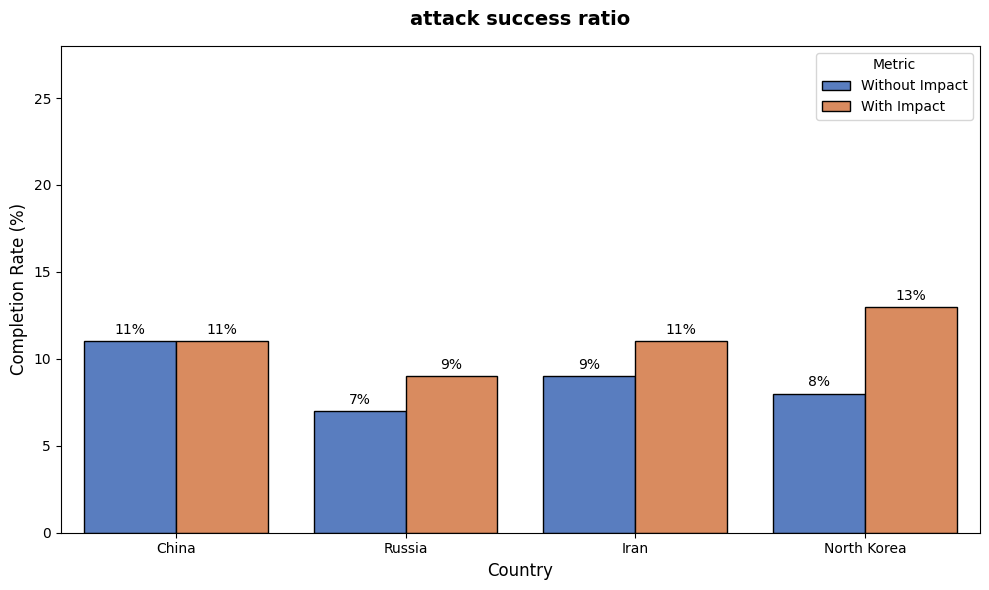

In [ ]:
target_countries = ['China', 'Russia', 'Iran', 'North Korea']
compare_data = []

# 💡 상위 10개 한정을 풀고, 국가별 전체 데이터를 순회하며 계산합니다.
for country in target_countries:
    # 해당 국가의 전체 데이터 필터링
    fe_df = main_df[main_df['Final_Country'] == country]
    all_tactic_counts = fe_df['tactics'].value_counts()
    
    # 해당 국가의 전체 Tactic 빈도수 총합 (분모)
    total = all_tactic_counts.sum()
    
    if total == 0:
        continue  # 데이터가 없는 국가 무시
    
    # 1. Impact 미포함 성공 횟수 (전체 데이터 기준)
    suc_no_impact = sum(count for tactic, count in all_tactic_counts.items() 
                        if 'collection' in str(tactic).lower() or 'exfiltration' in str(tactic).lower())
    
    # 2. Impact 포함 성공 횟수 (전체 데이터 기준)
    suc_with_impact = sum(count for tactic, count in all_tactic_counts.items() 
                          if 'collection' in str(tactic).lower() or 'exfiltration' in str(tactic).lower() or 'impact' in str(tactic).lower())
    
    compare_data.append({
        'Country': country,
        'Without Impact': round((suc_no_impact / total) * 100),
        'With Impact': round((suc_with_impact / total) * 100)
    })

df_compare = pd.DataFrame(compare_data)

# 시각화를 위해 데이터 포맷을 길게 변경 (Melt)
df_melted = pd.melt(df_compare, id_vars=['Country'], var_name='Metric', value_name='Rate')

# 🎨 그룹형 바 차트 그리기
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=df_melted, x='Country', y='Rate', hue='Metric', palette='muted', edgecolor='black')

# 바 위에 숫자 라벨 달아주기
for container in ax.containers:
    ax.bar_label(container, fmt='%d%%', padding=3)

# 💡 제목에 전체 데이터 기준(All Data)임을 명시하면 더 전문적으로 보입니다.
plt.title('attack success ratio', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Completion Rate (%)', fontsize=12)
plt.ylim(0, max(df_melted['Rate']) + 15) # 라벨이 잘리지 않도록 y축 여유 확보
plt.xlabel('Country', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
target_tactics = ['collection', 'exfiltration', 'impact']

# 1. 3대 핵심 텍틱에 해당하는 행들만 전체 데이터에서 필터링
condition = main_df['tactics'].fillna('').str.lower().apply(
    lambda x: any(tactic in x for tactic in target_tactics)
)
final_stage_df = main_df[condition]
print(final_stage_df['technique_id'].value_counts().head(10))

technique_id
T1560    61
T1005    45
T1074    44
T1056    34
T1114    30
T1567    29
T1041    27
T1119    21
T1213    19
T1113    19
Name: count, dtype: int64


In [10]:
import pandas as pd

target_tactics = ['collection', 'exfiltration', 'impact']
target_countries = ['China', 'Russia', 'Iran', 'North Korea']

# 1. 대상 4개 국가만 먼저 필터링
country_filtered_df = main_df[main_df['Final_Country'].isin(target_countries)]

# 2. 수집/유출/파괴 전술이 포함된 행을 찾기 위한 조건 설정
condition = country_filtered_df['tactics'].fillna('').str.lower().apply(
    lambda x: any(tactic in x for tactic in target_tactics)
)

raw_final_stage_df = country_filtered_df[condition].copy()

raw_final_stage_df = raw_final_stage_df.sort_values(by='Final_Country')



KeyError: 'Final_Country'

In [9]:
final_df = raw_final_stage_df

NameError: name 'raw_final_stage_df' is not defined

In [ ]:
final_df[final_df['Final_Country'] == 'China']['technique_id'].value_counts()

technique_id
T1560    39
T1074    29
T1005    22
T1567    16
T1041    14
T1056    13
T1114    12
T1048    11
T1119    10
T1213     6
T1039     5
T1557     4
T1486     4
T1113     4
T1030     3
T1537     3
T1657     2
T1020     2
T1052     2
T1490     2
T1530     2
T1602     1
T1029     1
T1531     1
T1496     1
T1489     1
T1485     1
Name: count, dtype: int64

In [ ]:
final_df[final_df['Final_Country'] == 'Iran']['technique_id'].value_counts()

technique_id
T1114    8
T1560    8
T1005    8
T1113    7
T1056    7
T1041    6
T1074    5
T1567    4
T1657    4
T1486    3
T1119    3
T1048    2
T1115    2
T1213    2
T1125    2
T1561    2
T1490    2
T1530    1
T1123    1
T1039    1
T1485    1
T1489    1
T1030    1
T1025    1
Name: count, dtype: int64

In [ ]:
final_df[final_df['Final_Country'] == 'Russia']['technique_id'].value_counts()

NameError: name 'final_df' is not defined

In [ ]:
final_df[final_df['Final_Country'] == 'North Korea']['technique_id'].value_counts()

NameError: name 'final_df' is not defined

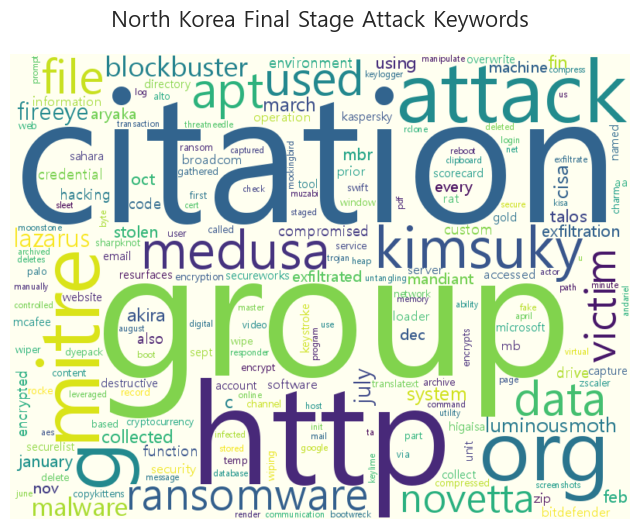

citation: 133회
group: 125회
http: 93회
attack: 93회
mitre: 93회
org: 93회
g: 87회
kimsuky: 49회
medusa: 42회
apt: 36회
data: 31회
used: 31회
file: 31회
ransomware: 28회
victim: 26회
novetta: 22회
blockbuster: 22회
malware: 20회
lazarus: 19회
fireeye: 18회


In [ ]:
nk_df = final_df[final_df['Final_Country'] == 'North Korea']
all_descriptions = ' '.join(
    nk_df['relationship_description'].dropna().astype(str)
)

processed_text = re.sub(r'[^\w]', ' ', all_descriptions)
processed_text = processed_text.lower().strip()

# 영문자만 남기기
EnWords = re.sub(r'[^a-zA-Z]+', ' ', processed_text)
stopWords = set(stopwords.words("english"))
lemma = WordNetLemmatizer()
# 토큰화 (단어 쪼개기)
EnWordsToken = word_tokenize(EnWords.lower())

# 불용어(stopWords) 제거 (※ 이미 stopWords 변수가 정의되어 있다고 가정)
EnWordsTokenStop = [w for w in EnWordsToken if w not in stopWords]

# 표제어 추출 (단어 원형 복원 ※ 이미 lemma 변수가 정의되어 있다고 가정)
EnWordsTokenStopLemma = [lemma.lemmatize(w) for w in EnWordsTokenStop]

words = EnWordsTokenStopLemma

word_count = Counter(words)

wc = WordCloud(font_path=font_path, background_color='ivory', width=800, height=600)
cloud = wc.generate_from_frequencies(word_count)

plt.figure(figsize=(8, 8))
plt.imshow(cloud, interpolation='bilinear')
plt.axis('off')
plt.title("North Korea Final Stage Attack Keywords", fontsize=16, pad=20)
plt.show()

for word, count in word_count.most_common(20):
    print(f"{word}: {count}회")

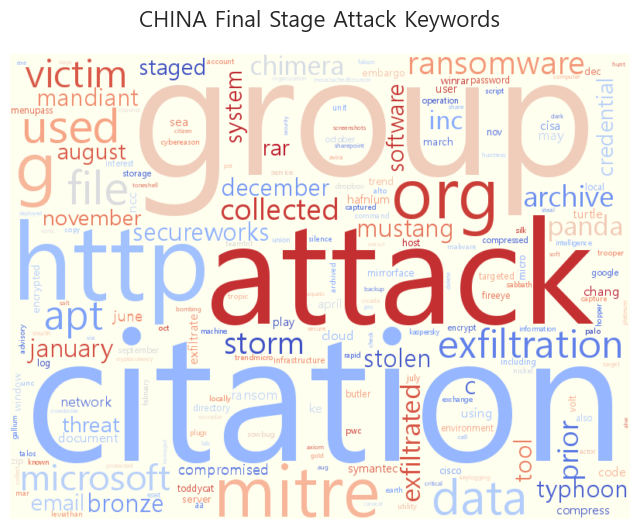

citation: 244회
group: 223회
attack: 204회
http: 202회
mitre: 202회
org: 202회
g: 186회
data: 75회
file: 67회
used: 66회
apt: 50회
exfiltration: 46회
victim: 45회
microsoft: 39회
ransomware: 32회
storm: 29회
collected: 26회
archive: 25회
prior: 23회
panda: 22회


In [ ]:
nk_df = final_df[final_df['Final_Country'] == 'China']
all_descriptions = ' '.join(
    nk_df['relationship_description'].dropna().astype(str)
)

processed_text = re.sub(r'[^\w]', ' ', all_descriptions)
processed_text = processed_text.lower().strip()

# 영문자만 남기기
EnWords = re.sub(r'[^a-zA-Z]+', ' ', processed_text)
stopWords = set(stopwords.words("english"))
lemma = WordNetLemmatizer()
# 토큰화 (단어 쪼개기)
EnWordsToken = word_tokenize(EnWords.lower())

# 불용어(stopWords) 제거 (※ 이미 stopWords 변수가 정의되어 있다고 가정)
EnWordsTokenStop = [w for w in EnWordsToken if w not in stopWords]

# 표제어 추출 (단어 원형 복원 ※ 이미 lemma 변수가 정의되어 있다고 가정)
EnWordsTokenStopLemma = [lemma.lemmatize(w) for w in EnWordsTokenStop]

words = EnWordsTokenStopLemma

word_count = Counter(words)

wc = WordCloud(font_path=font_path, background_color='ivory', width=800, height=600,colormap='coolwarm')
cloud = wc.generate_from_frequencies(word_count)

plt.figure(figsize=(8, 8))
plt.imshow(cloud, interpolation='bilinear')
plt.axis('off')
plt.title("CHINA Final Stage Attack Keywords", fontsize=16, pad=20)
plt.show()

for word, count in word_count.most_common(20):
    print(f"{word}: {count}회")

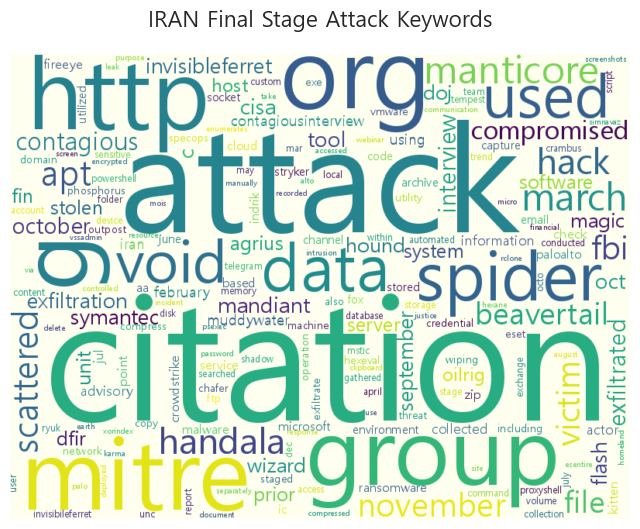

citation: 146회
attack: 110회
http: 109회
mitre: 109회
org: 109회
group: 99회
g: 99회
spider: 43회
data: 40회
used: 33회
void: 31회
manticore: 31회
march: 30회
handala: 26회
hack: 26회
apt: 25회
scattered: 25회
november: 22회
victim: 21회
fbi: 21회


In [ ]:
nk_df = final_df[final_df['Final_Country'] == 'Iran']
all_descriptions = ' '.join(
    nk_df['relationship_description'].dropna().astype(str)
)

processed_text = re.sub(r'[^\w]', ' ', all_descriptions)
processed_text = processed_text.lower().strip()

# 영문자만 남기기
EnWords = re.sub(r'[^a-zA-Z]+', ' ', processed_text)
stopWords = set(stopwords.words("english"))
lemma = WordNetLemmatizer()
# 토큰화 (단어 쪼개기)
EnWordsToken = word_tokenize(EnWords.lower())

# 불용어(stopWords) 제거 (※ 이미 stopWords 변수가 정의되어 있다고 가정)
EnWordsTokenStop = [w for w in EnWordsToken if w not in stopWords]

# 표제어 추출 (단어 원형 복원 ※ 이미 lemma 변수가 정의되어 있다고 가정)
EnWordsTokenStopLemma = [lemma.lemmatize(w) for w in EnWordsTokenStop]

words = EnWordsTokenStopLemma

word_count = Counter(words)

wc = WordCloud(font_path=font_path, background_color='ivory', width=800, height=600,colormap='viridis')
cloud = wc.generate_from_frequencies(word_count)

plt.figure(figsize=(8, 8))
plt.imshow(cloud, interpolation='bilinear')
plt.axis('off')
plt.title("IRAN Final Stage Attack Keywords", fontsize=16, pad=20)
plt.show()

for word, count in word_count.most_common(20):
    print(f"{word}: {count}회")

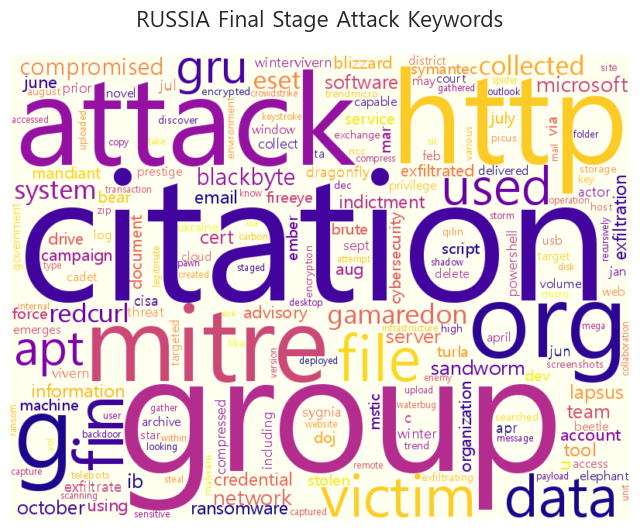

citation: 174회
group: 150회
http: 143회
attack: 138회
mitre: 136회
org: 136회
g: 124회
fin: 44회
file: 38회
victim: 37회
data: 36회
used: 29회
apt: 25회
gru: 24회
gamaredon: 24회
system: 23회
collected: 23회
eset: 22회
redcurl: 22회
blackbyte: 18회


In [ ]:
nk_df = final_df[final_df['Final_Country'] == 'Russia']
all_descriptions = ' '.join(
    nk_df['relationship_description'].dropna().astype(str)
)

processed_text = re.sub(r'[^\w]', ' ', all_descriptions)
processed_text = processed_text.lower().strip()

# 영문자만 남기기
EnWords = re.sub(r'[^a-zA-Z]+', ' ', processed_text)
stopWords = set(stopwords.words("english"))
lemma = WordNetLemmatizer()
# 토큰화 (단어 쪼개기)
EnWordsToken = word_tokenize(EnWords.lower())

# 불용어(stopWords) 제거 (※ 이미 stopWords 변수가 정의되어 있다고 가정)
EnWordsTokenStop = [w for w in EnWordsToken if w not in stopWords]

# 표제어 추출 (단어 원형 복원 ※ 이미 lemma 변수가 정의되어 있다고 가정)
EnWordsTokenStopLemma = [lemma.lemmatize(w) for w in EnWordsTokenStop]

words = EnWordsTokenStopLemma

word_count = Counter(words)

wc = WordCloud(font_path=font_path, background_color='ivory', width=800, height=600,colormap='plasma')
cloud = wc.generate_from_frequencies(word_count)

plt.figure(figsize=(8, 8))
plt.imshow(cloud, interpolation='bilinear')
plt.axis('off')
plt.title("RUSSIA Final Stage Attack Keywords", fontsize=16, pad=20)
plt.show()

for word, count in word_count.most_common(20):
    print(f"{word}: {count}회")

중국 핵심 단어: exfiltration (56회), microsoft (33회), fin (33회), mandiant (30회), exfiltrated (30회), archive (26회)
북한 핵심 단어: kimsuky (49회), ransomware (41회), medusa (39회), novetta (22회), blockbuster (22회), lazarus (19회)
러시아 핵심 단어: gru (24회), gamaredon (24회), eset (21회), sandworm (14회)
이란 핵심 단어: void (31회), manticore (31회), march (31회), handala (26회), hack (26회), fbi (21회), beavertail (15회)

1. 🇨🇳 중국 대응: "한국형 셰어드 인텔리전스(Shared Intelligence) 및 핵심 기술 금고화"
중국 키워드에서 exfiltration(대량 유출)과 archive(압축)가 압도적이었다는 것은, 그들이 국내 기업이나 연구소에 침투해 정보를 빼갈 때 우리가 유출 자체를 눈치채지 못하고 있었다는 뜻입니다.

보완 방안:

제로 트러스트 기반 데이터 보호(DLP) 강화: 중요 기밀 데이터(반도체, 방산, 바이오 등)가 보관된 서버는 외부 인터넷과 완전히 격리하고, 대용량 파일이 압축되거나 외부로 나가는 통로를 원천 차단하는 시스템을 의무화해야 합니다.

MS 인프라 취약점 공동 대응 시스템: microsoft가 핵심 키워드인 만큼, 국내 정부 기관 및 기업들이 사용하는 MS 가상화 환경이나 메일 서버의 취약점(1-Day) 패치를 강제하고 실시간으로 공유하는 민관 합동 관제 체계를 고도화해야 합니다.

2. 🇰🇵 북한 대응: "랜섬웨어 전담 대응 조직 운영 및 킴수키 시그니처 차단"
북한의 ransomware(랜섬웨어), kimsuky(킴수키) 키워드는 한국의 공공기관과 핵심 인프라를 상대로 한 실질적인 위협과 금전적 타격을 의미합니다.

보완 방안:

공공·금융 분야 백업 체계의 전면 개편: 북한 랜섬웨어에 감염되더라도 데이터 파괴(impact) 피해를 최소화할 수 있도록, 네트워크와 물리적으로 완전히 분리된 '오프라인 백업(Air-Gapped Backup)'을 의무화해야 합니다.

킴수키(Kimsuky) 전용 스피어피싱 방어망 구축: 킴수키의 주 무기는 한국 임직원을 노리는 교묘한 이메일 피싱입니다. 악성 첨부파일 문서(file, macro) 내의 코드를 자동으로 가상 공간에서 실행해 검사하는 EDR(단말 탐지) 및 이메일 격리 기술을 전면 도입해야 합니다.

3. 🇷🇺 러시아 대응: "국가 핵심 기반시설(OT)의 전시(戰時) 방어 시나리오 구축"
러시아 군 정보부(gru)와 샌드웜(sandworm)이 등장했다는 것은, 이들이 민간 해커 수준이 아니라 국가의 명령을 받고 상대국의 발전소, 가스망, 철도 등 기반시설을 마비시키는 파괴 공작에 특화되어 있다는 뜻입니다.

보완 방안:

폐쇄망(OT 영역)의 실시간 모니터링 체계 도입: 일반 IT 망과 분리되어 안전하다고 믿는 발전소나 국방 네트워크 안에서도 내부 정찰과 파괴 행위가 일어날 수 있음을 인지해야 합니다. 폐쇄망 전용 이상 트래픽 탐지 시스템을 도입해야 합니다.

우크라이나 전장 기반의 위협 인텔리전스(CTI) 흡수: 러시아의 gamaredon 등이 우크라이나에서 썼던 최신 사이버 무기 패턴을 글로벌 보안 기업(eset, microsoft)과의 정보 동맹을 통해 실시간으로 인도받아 국내 방어망에 선제 반영해야 합니다.

4. 🇮🇷 이란 대응: "지정학적 리스크에 따른 사이버 보복 공급망(Supply Chain) 점검"
이란의 void manticore, handala 같은 해킹 그룹은 지정학적 갈등(이스라엘-이란 등)이 발생했을 때 상대국을 향해 무차별 파괴 및 심리전 해킹(hack)을 감행합니다. 한국 역시 중동 정세나 동맹국 관계에 따라 언제든 보복 타깃이 될 수 있습니다.

보완 방안:

공급망 보안(Supply Chain Security) 강화: 이란 계열 해커들은 보안이 삼엄한 정부 기관을 직접 찌르기보다, 정부에 소프트웨어를 납품하는 중소 협력업체를 먼저 뚫고 들어오는 방식을 즐겨 씁니다. 공급망 전체의 보안 수준을 함께 끌어올리는 인증 제도가 필요합니다.

핵심 인물 및 기관에 대한 사이버 억제력 확보: fbi 등 국제 정보 기관과의 공조를 통해 위협 해커들의 신원과 인프라를 추적하고, 국제 사회와 함께 해킹 거점을 무력화하는 능동적 사이버 방어(Active Cyber Defense) 체계로 전환해야 합니다.

In [ ]:
main_df.count()

group_id                    4546
group_stix_id               4546
group_name                  4546
aliases                     4546
Matched_Name                2257
technique_id                4546
technique_stix_id           4546
technique_name              4546
is_subtechnique             4546
tactics                     4546
parent_technique_name       4018
relationship_description    4546
Country                     2770
Country_Source              4546
Final_Country               4546
dtype: int64

In [ ]:
main_df.head(0)

,group_id,group_stix_id,group_name,aliases,Matched_Name,technique_id,technique_stix_id,technique_name,is_subtechnique,tactics,parent_technique_name,relationship_description,Country,Country_Source,Final_Country


In [ ]:
# 1. 원본 데이터의 전체 크기 계산
total_count = len(main_df)

# 2. 'Final_Country' 컬럼의 빈도수(counts) 계산
# China: 1859, Russia: 1027, Iran: 744, North Korea: 643...
country_counts = main_df['Final_Country'].value_counts()

# 3. 타겟 국가 리스트 정의
target_countries = ['China', 'Russia', 'Iran', 'North Korea']

# 4. 딕셔너리 컴프리헨션을 사용해 비율(%) 계산 후 저장
# (국가별 빈도수 / 전체 크기) * 100 한 뒤 소수점 첫째 자리까지 반올림
country_percentages = {
    country: round((country_counts.get(country, 0) / total_count) * 100, 1)
    for country in target_countries
}

# 결과 딕셔너리 출력
print("=== 주요 4개국 비율(%) 저장 완료 ===")
print(country_percentages)
a =0
# PPT용 수치 정리 (복사용)
print("\n--- PPT 기재용 ---")
for country, percentage in country_percentages.items():
    a+=percentage
    print(f"{country}: {percentage}%")

print(f"{round(a,2)}%")

=== 주요 4개국 비율(%) 저장 완료 ===
{'China': np.float64(36.6), 'Russia': np.float64(25.4), 'Iran': np.float64(16.9), 'North Korea': np.float64(15.2)}

--- PPT 기재용 ---
China: 36.6%
Russia: 25.4%
Iran: 16.9%
North Korea: 15.2%
94.1%


In [ ]:
main_df.head()

,group_id,group_stix_id,group_name,aliases,Matched_Name,technique_id,technique_stix_id,technique_name,is_subtechnique,tactics,parent_technique_name,relationship_description,Country,Country_Source,Final_Country
0,G0119,intrusion-set--01e28736-2ffc-455b-9880-ed4d140...,Indrik Spider,"['Indrik Spider', 'Evil Corp', 'Manatee Tempes...",NaN,T1003,attack-pattern--65f2d882-3f41-4d48-8a06-29af77...,LSASS Memory,True,['credential-access'],OS Credential Dumping,[Indrik Spider](https://attack.mitre.org/group...,NaN,Unmatched,Iran
1,G1014,intrusion-set--b7f627e2-0817-4cd5-8d50-e75f8aa...,LuminousMoth,['LuminousMoth'],NaN,T1539,attack-pattern--10ffac09-e42d-4f56-ab20-db94c6...,Steal Web Session Cookie,False,['credential-access'],Steal Web Session Cookie,[LuminousMoth](https://attack.mitre.org/groups...,NaN,Unmatched,North Korea
2,G1051,intrusion-set--918da025-04bd-48af-b6c4-f3e4d1b...,Medusa Group,['Medusa Group'],NaN,T1490,attack-pattern--f5d8eed6-48a9-4cdf-a3d7-d1ffa9...,Inhibit System Recovery,False,['impact'],Inhibit System Recovery,[Medusa Group](https://attack.mitre.org/groups...,NaN,Unmatched,North Korea
3,G0102,intrusion-set--dd2d9ca6-505b-4860-a604-233685b...,Wizard Spider,"['Wizard Spider', 'UNC1878', 'TEMP.MixMaster',...",NaN,T1136,attack-pattern--635cbe30-392d-4e27-978e-667743...,Local Account,True,['persistence'],Create Account,[Wizard Spider](https://attack.mitre.org/group...,NaN,Unmatched,Iran
4,G0046,intrusion-set--3753cc21-2dae-4dfb-8481-d004e74...,FIN7,"['FIN7', 'GOLD NIAGARA', 'ITG14', 'Carbon Spid...",FIN7,T1204,attack-pattern--ef67e13e-5598-4adc-bdb2-998225...,Malicious Link,True,['execution'],User Execution,[FIN7](https://attack.mitre.org/groups/G0046) ...,Russia,Wikipedia,Russia


In [ ]:
# 'south korea'가 포함된 행 필터링 (대소문자 구분 없음)
result_df = main_df[main_df['relationship_description'].str.contains('south korea', case=False, na=False)]

In [ ]:
result_df.count()

NameError: name 'result_df' is not defined

In [ ]:
csia_df = pd.read_csv('./midterm/csia_origin.csv')

In [ ]:
csia_df.head()

,국가,공격코드(경보),출판일,제목,설명,상세URL,상세본문
0,중국,AA26-113A,"April 23, 2026",Defending Against China-Nexus Covert Networks ...,"The advisory outlines tactics, techniques, pro...",https://www.cisa.gov/news-events/cybersecurity...,Defending against china-nexus covert networks ...
1,중국,AA25-239A,"August 27, 2025",Countering Chinese State-Sponsored Actors Comp...,"The National Security Agency (NSA), Cybersecur...",https://www.cisa.gov/news-events/cybersecurity...,Executive summary\nPeople’s Republic of China ...
2,중국,NaN,"December 18, 2024",Mobile Communications Best Practice Guidance,This guidance was crafted in response to ident...,https://www.cisa.gov/resources-tools/resources...,This guidance was crafted in response to ident...
3,중국,NaN,"December 4, 2024",Enhanced Visibility and Hardening Guidance for...,CISA and its partners warn that People’s Repub...,https://www.cisa.gov/resources-tools/resources...,Introduction\nThe Cybersecurity and Infrastruc...
4,중국,AA24-190A,"July 8, 2024",People’s Republic of China (PRC) Ministry of S...,CISA and its partners published this advisory ...,https://www.cisa.gov/news-events/cybersecurity...,"Overview\nBackground\nThis advisory, authored ..."


In [ ]:
csia_df.count()

국가          95
공격코드(경보)    79
출판일         95
제목          95
설명          95
상세URL       95
상세본문        95
dtype: int64

In [ ]:
result_df = csia_df[csia_df['상세본문'].str.contains('south korea', case=False, na=False)]

In [ ]:
result_df.count()

국가          6
공격코드(경보)    6
출판일         6
제목          6
설명          6
상세URL       6
상세본문        6
dtype: int64

In [ ]:
csis_df = pd.read_csv('./midterm/csis.csv',encoding='cp949')

In [ ]:
csis_df.head()

,Date of report,Target & Attacker,details,Target,group_name,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9
0,26-Mar,European Commission (Attacker: Unknown),The European Commission claims it was targeted...,European Commission,Unknown,NaN,NaN,NaN,NaN,NaN
1,26-Mar,"Foster City, California (Attacker: Unknown)","Foster City, California was forced to pause al...","Foster City, California",Unknown,NaN,NaN,NaN,NaN,NaN
2,26-Mar,Stryker (Attacker: Handala),Medical device maker Stryker claimed a cyberat...,Stryker,Handala,NaN,NaN,NaN,NaN,NaN
3,26-Mar,Telus (Attacker: ShinyHunters),Canadian telecommunications firm Telus reporte...,Telus,ShinyHunters,NaN,NaN,NaN,NaN,NaN
4,26-Feb,Singapore Telecom Providers (Attacker: UNC3886),Singapore's Cyber Security Agency revealed tha...,Singapore Telecom Providers,UNC3886,NaN,NaN,NaN,NaN,NaN


In [ ]:
result_df = csis_df[csis_df['Target'].str.contains('south korea', case=False, na=False)]

In [ ]:
csis_df.count()

Date of report       1209
Target & Attacker    1209
details              1209
Target               1209
group_name           1209
Unnamed: 5              1
Unnamed: 6              1
Unnamed: 7              1
Unnamed: 8              1
Unnamed: 9              1
dtype: int64

In [ ]:
result_df.count()

Date of report       28
Target & Attacker    28
details              28
Target               28
group_name           28
Unnamed: 5            0
Unnamed: 6            0
Unnamed: 7            0
Unnamed: 8            0
Unnamed: 9            0
dtype: int64

In [ ]:
cot_df = pd.read_csv('./midterm/cot_나라4개합친거.csv')

In [ ]:
cot_df.head()

,Title,URL,Description,Date_of_report,State_sponsor,Affiliations,Type_of_incident,Target_category,Suspected_victims,Victim_government_reaction,Policy_response,technique_id
0,"Targeting of Teamviewer, a German-based compan...",https://www.cfr.org/cyber-operations/targeting...,"Teamviewer, a German-based company that makes ...",2024-06,Russian Federation,APT 29,Espionage,Private sector,"Teamviewer, a German-based company that makes ...",Unknown,Unknown,T1020
1,"Targeting of TVP, a public service broadcaster...",https://www.cfr.org/cyber-operations/targeting...,The Polish deputy minister of digital affairs ...,2024-06,Russian Federation,Believed to be affiliated with the Russian gov...,Denial of service,Civil society,Polish public broadcaster TVP,Unknown,Confirmation,T1498
2,Targeting of Ukrainian citizens who were conce...,https://www.cfr.org/cyber-operations/targeting...,Cloudfare?셲 security team identified a phishin...,2024-05,Russian Federation,FlyingYeti,Espionage,Civil society,Ukrainian citizens,Yes,Confirmation: Suspected state sponsor response...,T1020
3,FlyingYeti,https://www.cfr.org/cyber-operations/flyingyeti,FlyingYeti is a threat actor known primarily f...,2024-05,Russian Federation,Believed to be affiliated with the Russian gov...,Espionage,Civil society: Military,Ukrainian military entities and Ukrainian citi...,Unknown,Confirmation: Suspected state sponsor response...,T1020
4,UAC-0188,https://www.cfr.org/cyber-operations/uac-0188,UAC-0188 is a Russian threat actor that has be...,2024-05,Russian Federation,Believed to be affiliated with the Russian gov...,Espionage,Private sector,U.S. and European financial and insurance inst...,Yes,Confirmation: Suspected state sponsor response...,T1020


In [ ]:
cot_df.count()

Title                         674
URL                           674
Description                   674
Date_of_report                671
State_sponsor                 674
Affiliations                  590
Type_of_incident              650
Target_category               656
Suspected_victims             640
Victim_government_reaction    475
Policy_response               272
technique_id                  650
dtype: int64

In [ ]:
result_df = cot_df[cot_df['Title'].str.contains('south korea', case=False, na=False)]

In [ ]:
result_df.count()

Title                         31
URL                           31
Description                   31
Date_of_report                31
State_sponsor                 31
Affiliations                  28
Type_of_incident              31
Target_category               30
Suspected_victims             30
Victim_government_reaction    25
Policy_response               15
technique_id                  31
dtype: int64